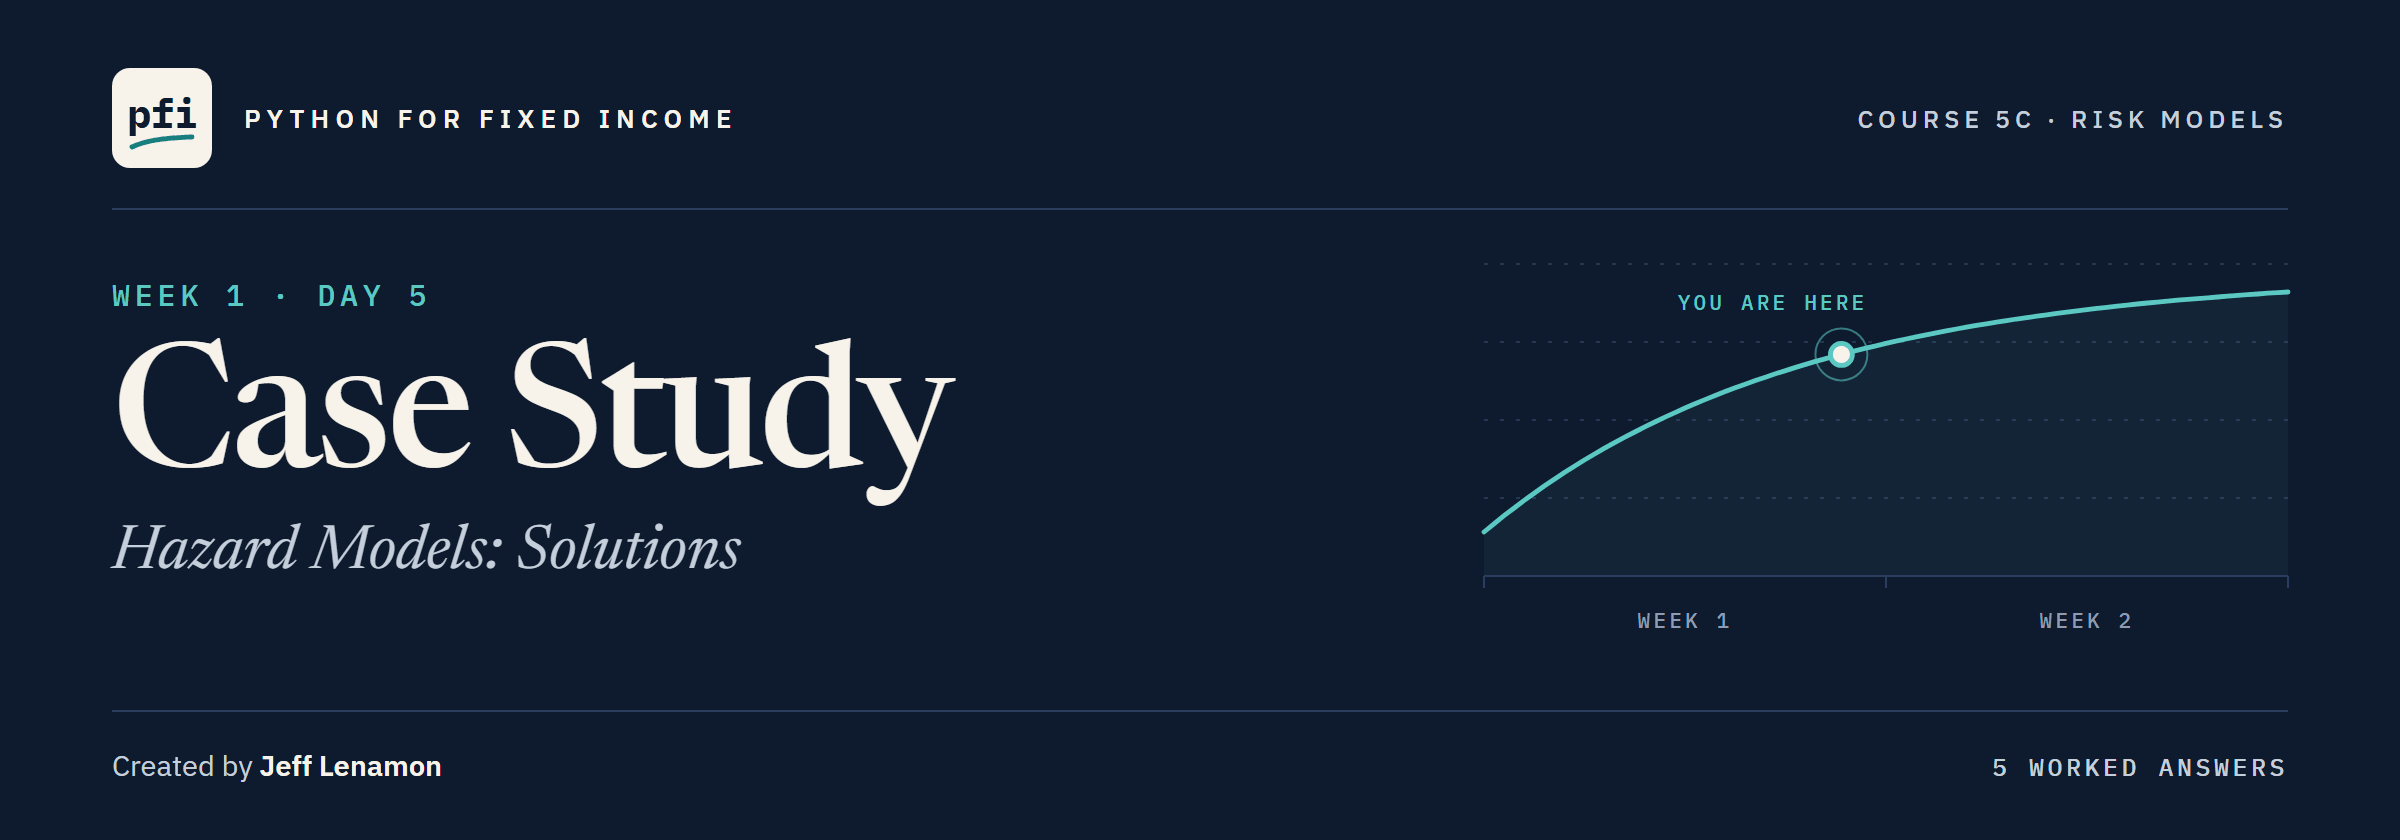

# Case Study: Hazard Models: Solutions

Week 1, Day 5. The full notebook with every exercise worked. Try each one yourself first.

**Data:** `course5c_cohort.csv`, 4,000 invented firms followed year by year over 20 study years to default, exit, or the end: **synthetic**, ids only, no calendar years, and no agency default statistic.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05c_risk_models/week1/day5/05_case_study_hazard_models_solutions.ipynb)

# Problem Statement

## Business Context

Day 4 drew survival curves by rating at entry, as if a firm never changed.
The risk team wants each firm's own numbers, year by year, inside the hazard.
Two published routes do it: the Cox model, and a logistic regression on firm-years (Shumway, Journal of Business 74 (1), 2001, pages 101 to 124, https://doi.org/10.1086/209665).
Then a colleague asks: fitted only on the study years before each year, would the model have ranked and sized the defaults of study years 8 to 14?
A hazard ratio multiplies the fitted hazard, an association in this file, never a cause.
The output is the model's default probability for that firm-year of these invented firms, never a statement about a real firm or a coming year.

## Objectives

Read firm-years as intervals on the years-since-entry clock, and check a feature by study year.
Work a Cox partial likelihood by hand and match statsmodels.
Fit `PHReg`, read hazard ratios, and set `ties` and `strata`.
Test indicators one at a time and together, and check proportional hazards.
Fit a discrete-time hazard and turn yearly hazards into survival.
Score a model walk-forward by study year on ranking and level, and compare models.

## Data Dictionary

`course5c_cohort.csv`, one row per firm per study year:

1. `firm_id`: the firm, an invented id
2. `study_year`: 1 to 20, never a calendar year; today reads 1 to 14
3. `years_since_entry`: 1 in the firm's first year
4. `sector`: one of ten invented sector labels
5. `rating` and `rating_score`: the rating, and its score from 1 (AAA) to 18 (CCC)
6. `leverage`: debt to EBITDA, times
7. `coverage`: EBITDA to interest, times
8. `default`: 1 in the year the firm defaulted
9. `exit`: 1 in the year the firm left for a reason unrelated to default

Rating, leverage and coverage are dated at the start of the year.
`ratings.csv` is the course's rating scale: each `rating` and its `bucket`.

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# chi-squared p-values (Day 2), the logistic and Cox fits, and Day 4's survival curve
from scipy import stats
import statsmodels.api as sm
from statsmodels.duration.survfunc import SurvfuncRight

# to score a ranking (Course 4's Day 8) and a level (Course 5's Day 13)
from sklearn.metrics import roc_auc_score, brier_score_loss

# to draw charts, a log colour scale, and a slider
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import seaborn as sns
from ipywidgets import interact

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

# Loading the Data

## Reading the Cohort and the Rating Scale

In [3]:
# the synthetic cohort, one row per firm per study year, and the course's rating scale (a lookup)
cohort = pd.read_csv(DATA + "course5c_cohort.csv")
ratings = pd.read_csv(DATA + "ratings.csv")
print(cohort.shape, "| rating scale:", ratings.shape)

(29615, 10) | rating scale: (18, 4)


## The Development Years Only

In [4]:
# Day 3's cut: study years 1 to 14; the later years are counted and left alone
DEVELOPMENT_END = 14
development = cohort[cohort["study_year"] <= DEVELOPMENT_END].copy()
print("Development firm-years:", len(development), "| firms:", development["firm_id"].nunique(), "| defaults:", development["default"].sum())
print("Held-out firm-years:", len(cohort) - len(development))

Development firm-years: 18503 | firms: 3504 | defaults: 345
Held-out firm-years: 11112


**Today fits and scores inside study years 1 to 14.**

# Data Overview

## One Firm, Year by Year

The file is already a **person-period table**: one row per firm per year at risk, Day 3's firm-year.

In [5]:
# each firm's step in rating score from one year to the next (Course 3's .diff(), within each firm)
step = development.groupby("firm_id")["rating_score"].diff()
print("Year-on-year steps:", step.notna().sum(), "| to a higher score:", (step > 0).sum(), "| to a lower score:", (step < 0).sum())

# firm F0009, year by year: its inputs are read at the start of each year
development[development["firm_id"] == "F0009"][["study_year", "years_since_entry", "rating", "rating_score", "leverage", "coverage", "default"]]

Year-on-year steps: 14999 | to a higher score: 1213 | to a lower score: 908


,study_year,years_since_entry,rating,rating_score,leverage,coverage,default
74,1,1,B,15,5.36,3.22,0
75,2,2,B-,16,5.09,8.94,0
76,3,3,B-,16,4.83,4.74,0
77,4,4,B-,16,4.62,3.51,0
78,5,5,B-,16,4.59,6.56,0
79,6,6,B-,16,4.68,1.99,0
80,7,7,B-,16,4.80,6.99,0
81,8,8,B-,16,4.63,3.72,0
82,9,9,B-,16,4.61,10.65,1


F0009 entered at B, moved to B- in its second year, and defaulted in its ninth; leverage and coverage change every row.

A higher score is a lower rating: more steps went down the scale.

## When the Defaults Fall

In [6]:
# the years since entry at which the defaults fall
print(development.loc[development["default"] == 1, "years_since_entry"].value_counts().sort_index().to_dict())

{1: 62, 2: 77, 3: 59, 4: 43, 5: 29, 6: 20, 7: 14, 8: 15, 9: 8, 10: 11, 11: 2, 12: 3, 13: 1, 14: 1}


The 345 defaults fall on 14 whole years, so most default times are shared by several firms: a **tie**, which the Cox model must settle.

**Inputs move every year, and the clock ticks in whole years.**

# Exploratory Data Analysis

## Two Clocks on One Chart

A firm's rows climb one year across and one year up, a 45-degree diagonal; firms that entered in the same study year share it, an **entry cohort**.

In [7]:
# the counted hazard of every cell, percent a year: study year across, years since entry up
cells = development.groupby(["years_since_entry", "study_year"])["default"].agg(["size", "sum"])
surface = (100 * cells["sum"] / cells["size"]).unstack()
print("Cells:", len(cells), "| firm-years a cell:", cells["size"].min(), "to", cells["size"].max(), "| cells with no default:", (cells["sum"] == 0).sum())

# the two margins: each study year's counted hazard, and each year since entry's
by_study_year = 100 * development.groupby("study_year")["default"].mean()
by_age = 100 * development.groupby("years_since_entry")["default"].mean()
print("Study years:", by_study_year.round(2).to_dict())
print("Years since entry:", by_age.round(2).to_dict())

Cells: 105 | firm-years a cell: 73 to 281 | cells with no default: 11
Study years: {1: 0.78, 2: 1.89, 3: 1.26, 4: 1.95, 5: 2.39, 6: 1.92, 7: 2.41, 8: 1.56, 9: 1.98, 10: 2.61, 11: 1.12, 12: 1.21, 13: 1.99, 14: 2.14}
Years since entry: {1: 1.77, 2: 2.61, 3: 2.36, 4: 2.04, 5: 1.68, 6: 1.41, 7: 1.23, 8: 1.64, 9: 1.09, 10: 1.92, 11: 0.48, 12: 1.06, 13: 0.6, 14: 1.37}


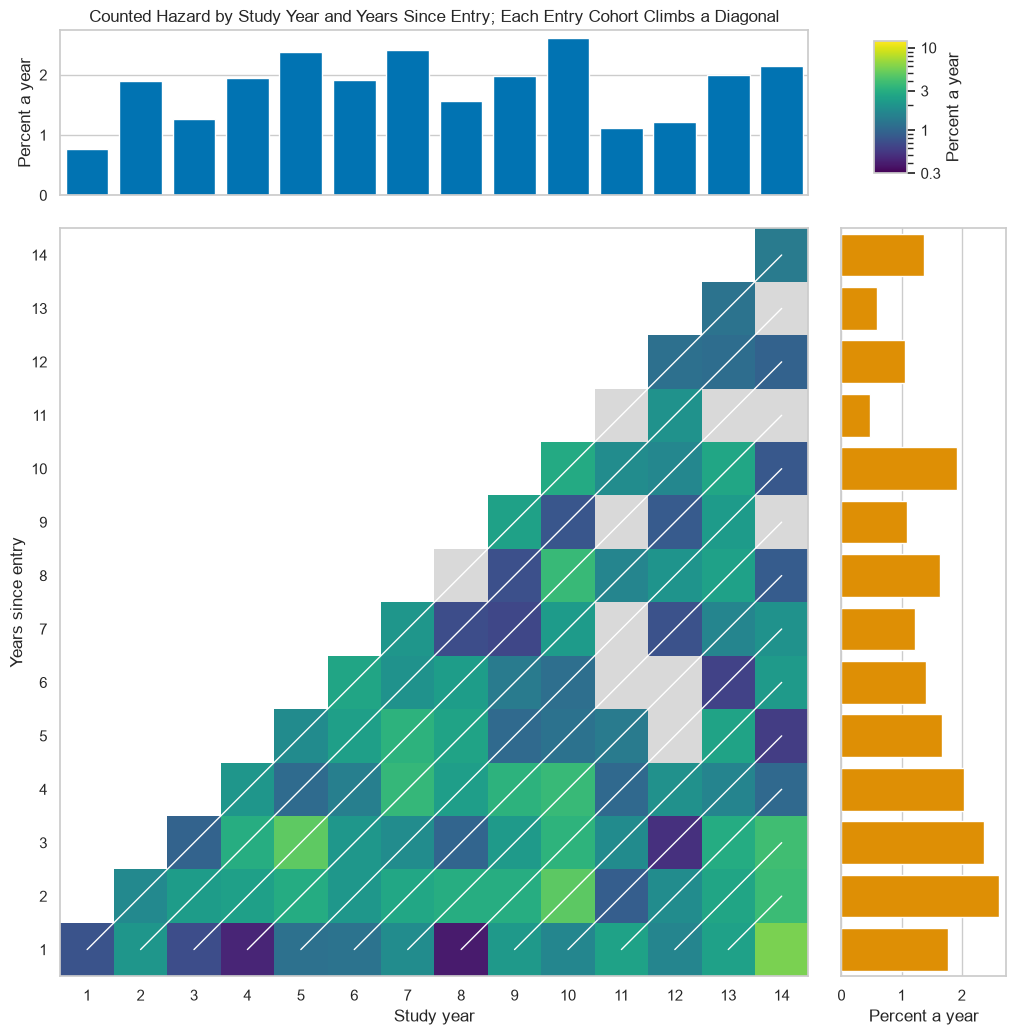

In [8]:
# the showpiece: fig.add_axes([left, bottom, width, height]) sets each panel as shares of the square figure, so the cells come out square
fig = plt.figure(figsize=(11, 11))
main, top, side, scale = [fig.add_axes(box) for box in ([0.08, 0.07, 0.68, 0.68], [0.08, 0.78, 0.68, 0.15], [0.79, 0.07, 0.15, 0.68], [0.82, 0.8, 0.03, 0.12])]
edges = np.arange(0.5, 15)
# pcolormesh colours a grid of cells between these edges; LogNorm(0.3, 12) spreads the colours on a log scale
mesh = main.pcolormesh(edges, edges, surface.where(surface > 0), norm=LogNorm(0.3, 12), cmap="viridis")
main.pcolormesh(edges, edges, np.where(surface == 0, 1.0, np.nan), cmap="Greys", vmin=0, vmax=4)
for entry in range(1, 15):
    main.plot([entry, 14], [1, 15 - entry], color="white", linewidth=1)
main.set_aspect("equal")
main.grid(False)
main.set(xlim=(0.5, 14.5), ylim=(0.5, 14.5), xticks=range(1, 15), yticks=range(1, 15), xlabel="Study year", ylabel="Years since entry")
top.bar(by_study_year.index, by_study_year, color="C0")
top.set(xlim=(0.5, 14.5), xticks=[], ylabel="Percent a year", title="Counted Hazard by Study Year and Years Since Entry; Each Entry Cohort Climbs a Diagonal")
side.barh(by_age.index, by_age, color="C1")
side.set(ylim=(0.5, 14.5), yticks=[], xlabel="Percent a year")
# cax= puts the colour key in its own small panel
fig.colorbar(mesh, cax=scale, label="Percent a year", ticks=[0.3, 1, 3, 10], format="%g")
plt.show()

In [9]:
# one diagonal read along: the firms that entered in study year 3
development["entry_year"] = development["study_year"] - development["years_since_entry"] + 1
entered_3 = development[development["entry_year"] == 3]
print("Firms:", entered_3["firm_id"].nunique(), "| percent a year by years since entry:", (100 * entered_3.groupby("years_since_entry")["default"].mean()).round(2).to_dict())
print(f"Over their twelve years: {100 * entered_3['default'].mean():.2f} percent a year")

Firms: 281 | percent a year by years since entry: {1: 0.71, 2: 2.39, 3: 4.82, 4: 1.45, 5: 3.21, 6: 2.31, 7: 0.65, 8: 3.6, 9: 0.0, 10: 1.65, 11: 0.0, 12: 0.94}
Over their twelve years: 1.96 percent a year


Grey cells counted no default; the blank half holds ages no firm could reach by that study year.

The top margin runs from 0.78 percent a year in study year 1 to 2.61 in year 10, Day 3's clustering by study year; each column holds every age in that year, so a cell alone is noisy.

The right margin peaks at 2.61 in the second year since entry, Day 4's bump in years 2 to 4.

Along one diagonal, the year-3 entrants, the largest cohort, ran 0.71, 2.39 and 4.82 percent in their first three years, then fell back.

The highest cell is the year-14 entrants' first year, 5.75 percent on 261 firm-years; Day 8 compares the firms entering in study years 11 to 14 with earlier entrants.

## Default Rate by Leverage, Coverage and Rating

In [10]:
# the counted hazard in each fifth of leverage and of coverage (Course 1's pd.qcut), percent a year
by_leverage = 100 * development.groupby(pd.qcut(development["leverage"], 5), observed=True)["default"].mean()
by_coverage = 100 * development.groupby(pd.qcut(development["coverage"], 5), observed=True)["default"].mean()
fifths = pd.DataFrame({"leverage": by_leverage.to_numpy(), "coverage": by_coverage.to_numpy()}, index=["lowest", "2", "3", "4", "highest"])
fifths.round(2)

,leverage,coverage
lowest,0.05,5.24
2,0.32,2.09
3,0.87,1.22
4,1.76,0.59
highest,6.34,0.16


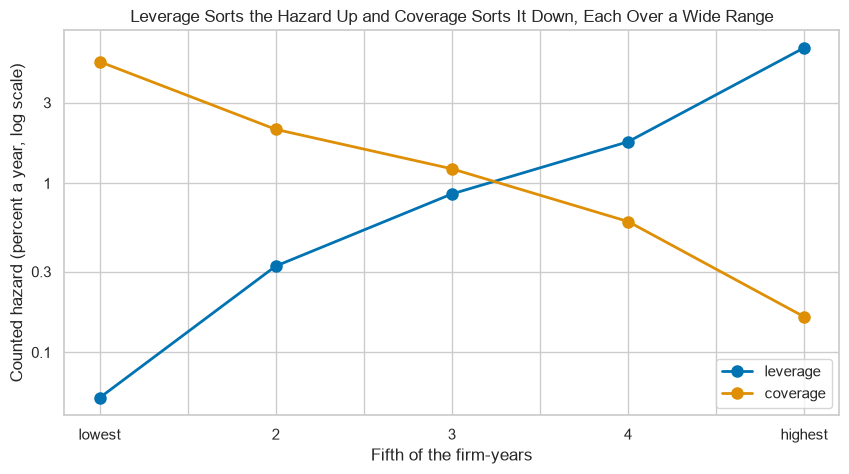

In [11]:
# the two columns on a log axis
fifths.plot(marker="o", linewidth=2, markersize=8)
plt.yscale("log")
plt.yticks([0.1, 0.3, 1, 3], ["0.1", "0.3", "1", "3"])
plt.xlabel("Fifth of the firm-years")
plt.ylabel("Counted hazard (percent a year, log scale)")
plt.title("Leverage Sorts the Hazard Up and Coverage Sorts It Down, Each Over a Wide Range")
plt.show()

In [12]:
# how rating, leverage and coverage move together (Course 1's .corr()), coverage on a log scale
inputs = pd.DataFrame({"rating_score": development["rating_score"], "leverage": development["leverage"], "log coverage": np.log(development["coverage"])})
inputs.corr().round(3)

,rating_score,leverage,log coverage
rating_score,1.000,0.725,-0.491
leverage,0.725,1.000,-0.673
log coverage,-0.491,-0.673,1.000


**Each input sorts the hazard, and they move together; a model has to share the credit out.**

# Data Preparation for Modeling

## Two Features

`log_coverage` is the log of coverage, so halving coverage moves it by the same amount at any level.
`early_years` is 1 in years 2 to 4 since entry, Day 4's bump.

In [13]:
# the two features, and the four the models read
development["log_coverage"] = np.log(development["coverage"])
development["early_years"] = development["years_since_entry"].between(2, 4).astype(int)
FEATURES = ["rating_score", "leverage", "log_coverage", "early_years"]
print("Coverage:", development["coverage"].min(), "to", development["coverage"].max(), "| share of firm-years with early_years 1:", round(development["early_years"].mean(), 4))

Coverage: 0.37 to 70.43 | share of firm-years with early_years 1: 0.4079


## The Cut Test by Study Year

Course 5B's Day 2 cut test, by study year: year 10's features built from rows up to year 10 must match those built from every row.

In [14]:
# the features from study years 1 to 10 only, against the same features from every development row
upto_10 = cohort[cohort["study_year"] <= 10].copy()
upto_10["log_coverage"] = np.log(upto_10["coverage"])
upto_10["early_years"] = upto_10["years_since_entry"].between(2, 4).astype(int)
columns = ["firm_id", "log_coverage", "early_years"]
same = upto_10.loc[upto_10["study_year"] == 10, columns].reset_index(drop=True).equals(development.loc[development["study_year"] == 10, columns].reset_index(drop=True))
print("Year 10's rows:", (upto_10["study_year"] == 10).sum(), "| the same either way:", same)

Year 10's rows: 1724 | the same either way: True


**Every input is known at the start of its year; the test shows it.**

# The Cox Model by Hand

## The Model and the Risk Set

The **Cox model** writes a firm-year's hazard as a **baseline hazard**, one for each year since entry and left free, times exp(b x).
x is the firm-year's input, and exp(b) is the **hazard ratio**: what one more unit of x multiplies the hazard by.
At a default time the **risk set** is the firms at risk then.

![Four firms as rows of intervals on the years-since-entry clock, each interval from t - 1 to t carrying that year's inputs x(t). A line at year 3 crosses one interval per firm still watched in year 3: the risk set. A firm that left after year 2 is not in it. With entry set to t - 1 the year-4 rows start on the line and count again; an entry at t - 0.5, inside the year, counts each firm once](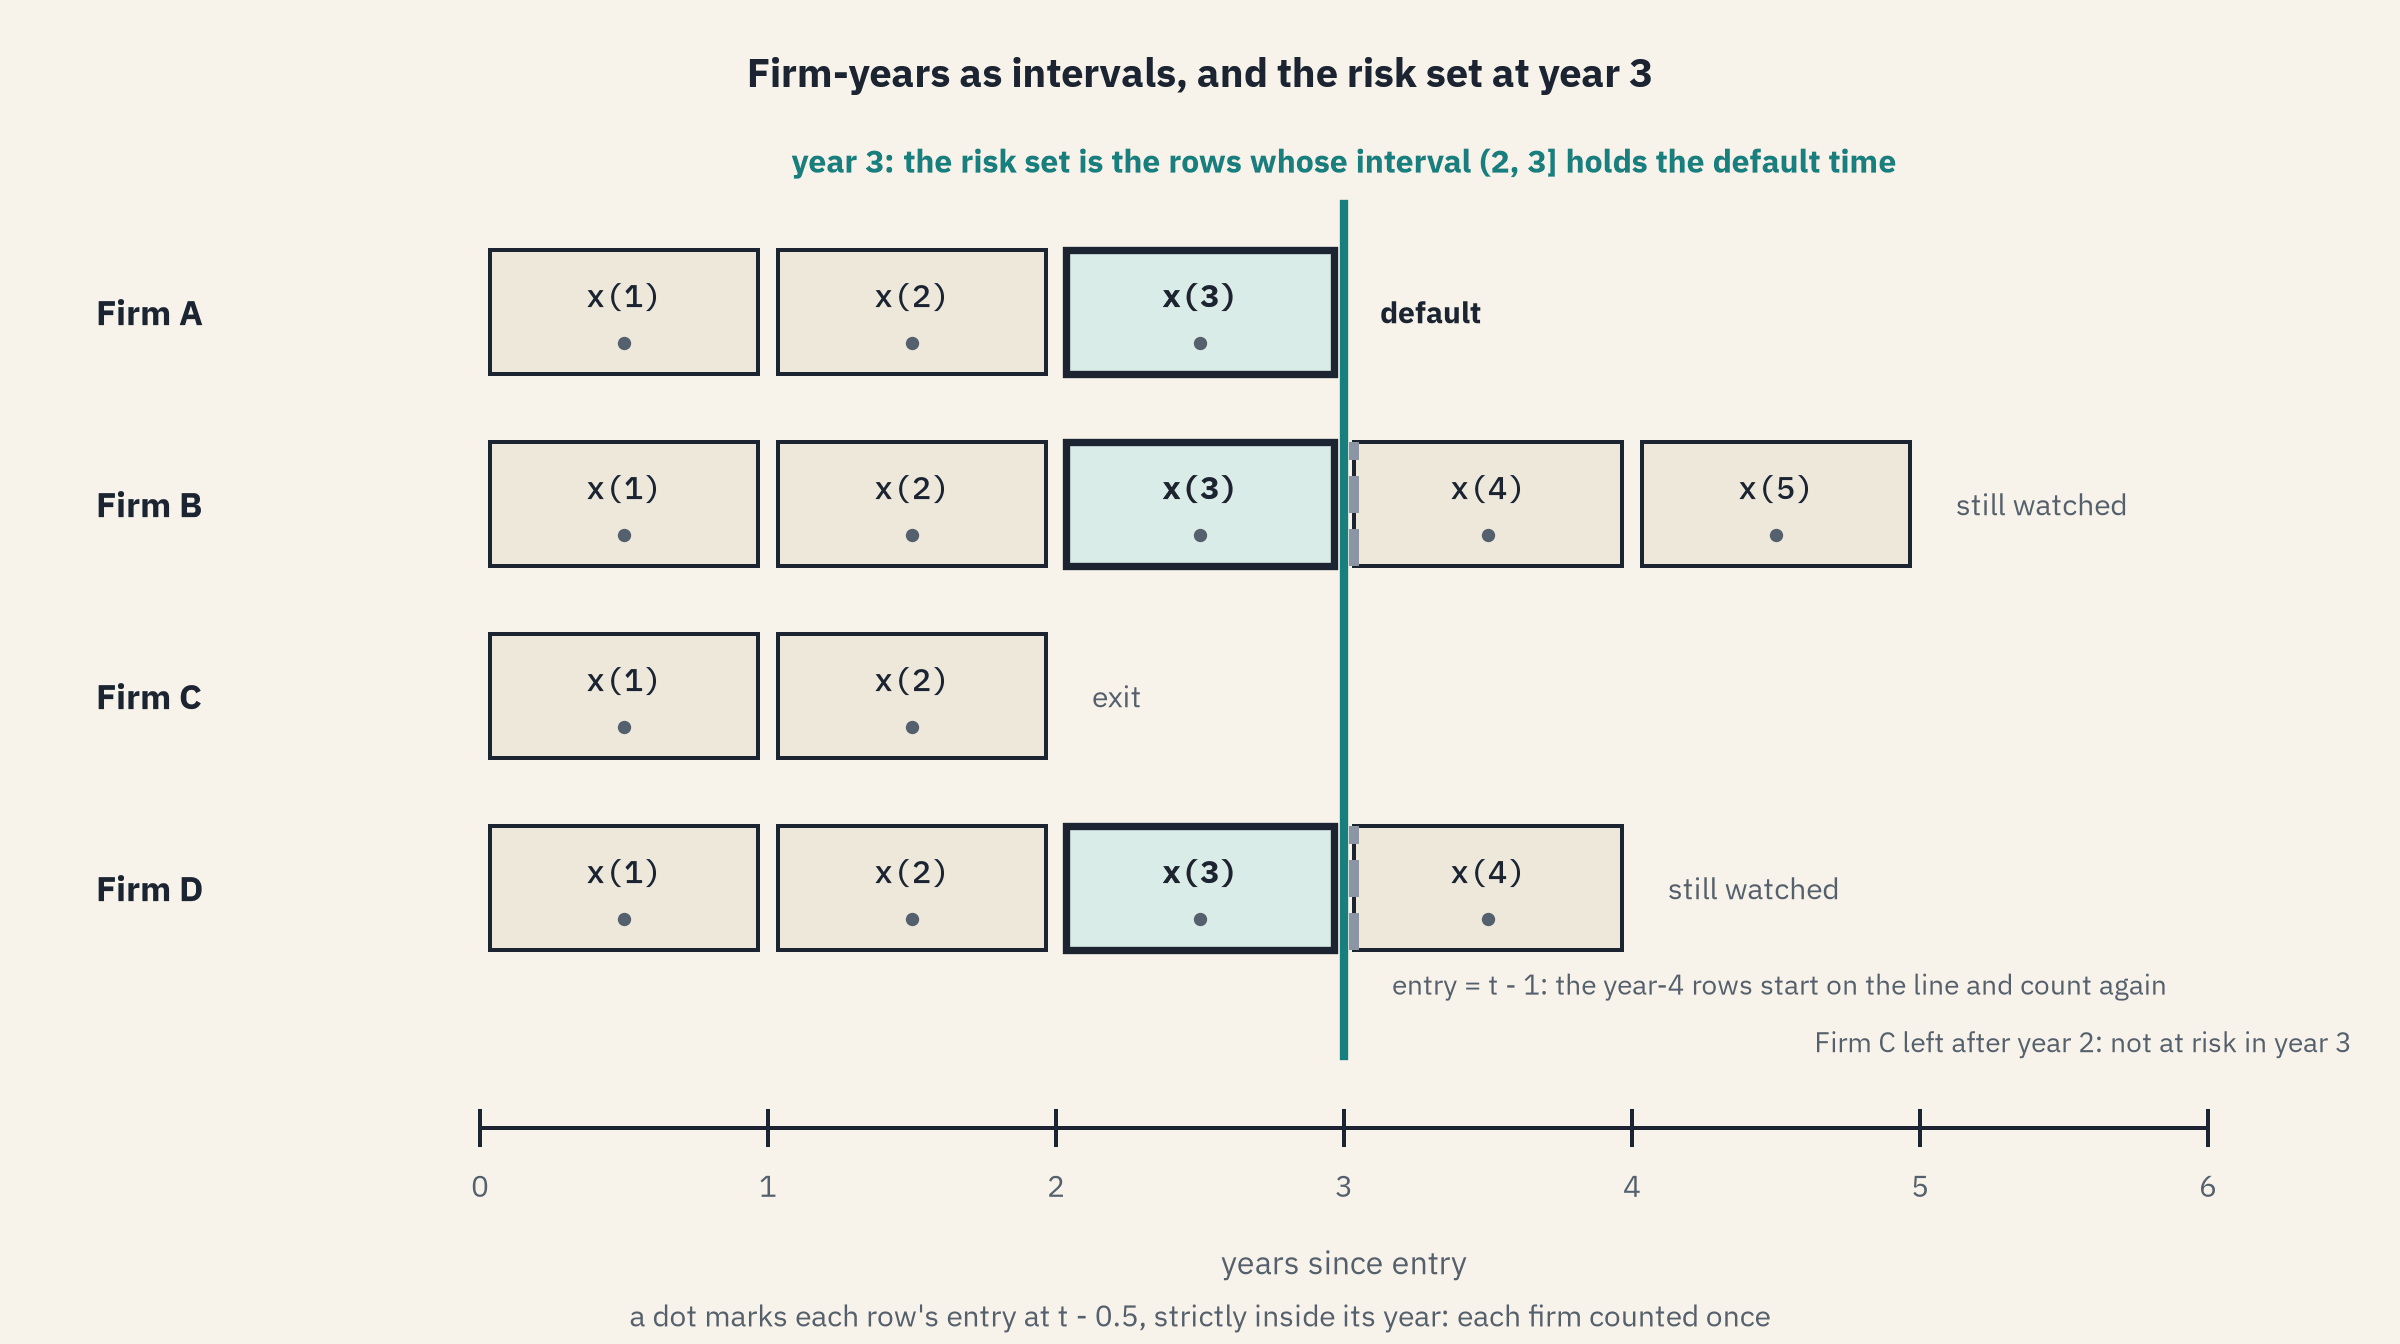)

## Day 4's Ten Firms

In [15]:
# Day 4's firms table, and its ten firms drawn as Day 4 drew them: 3 that defaulted, then 7 others
firms = development.groupby("firm_id").agg(years=("years_since_entry", "max"), defaulted=("default", "max"),
                                           exited=("exit", "max"), entry_year=("study_year", "min"),
                                           entry_rating=("rating", "first"))
firms["entry_bucket"] = firms["entry_rating"].map(ratings.set_index("rating")["bucket"])
firms["group"] = firms["entry_bucket"].map({"AAA": "IG", "AA": "IG", "A": "IG", "BBB": "IG", "BB": "BB", "B": "B", "CCC": "CCC"})
rng = np.random.default_rng(SEED)
picked = list(rng.choice(firms.index[firms["defaulted"] == 1], 3, replace=False)) + list(rng.choice(firms.index[firms["defaulted"] == 0], 7, replace=False))
ten = development[development["firm_id"].isin(picked)]
print("Firm-years:", len(ten), "| defaults at years since entry:", sorted(ten.loc[ten["default"] == 1, "years_since_entry"].tolist()))

Firm-years: 39 | defaults at years since entry: [3, 3, 5]


Each firm's share of the year's hazard is exp(b x) over the sum across the risk set.
At b = 0 the rating does nothing, and the firms share alike.

In [16]:
# year 3's risk set: one row per firm still watched in its third year, its rating score that year, and its share at b = 0
year_3 = ten[ten["years_since_entry"] == 3][["firm_id", "rating_score", "default"]]
weight = np.exp(0 * year_3["rating_score"])
year_3.assign(share=weight / weight.sum()).round(4)

,firm_id,rating_score,default,share
2272,F0248,17,1,0.1667
6877,F0735,4,0,0.1667
16845,F1882,18,1,0.1667
16905,F1889,11,0,0.1667
19689,F2238,15,0,0.1667
21536,F2479,12,0,0.1667


**Predict 1**

Year 3's six firms score 4, 11, 12, 15, 17 and 18.

Q. If each notch down the scale doubled the hazard (b = ln 2), what share of year 3's hazard falls on the score-18 firm? Write down a percent.

## Who Defaults Among Those at Risk

In [17]:
# the shares at b = ln 2: each notch doubles the hazard
weight = np.exp(np.log(2) * year_3["rating_score"])
year_3.assign(share=weight / weight.sum()).round(4)

,firm_id,rating_score,default,share
2272,F0248,17,1,0.3033
6877,F0735,4,0,0.0000
16845,F1882,18,1,0.6066
16905,F1889,11,0,0.0047
19689,F2238,15,0,0.0758
21536,F2479,12,0,0.0095


The score-18 firm takes six tenths of the year's hazard, and it defaulted; so did the score-17 firm, with three tenths.

The **partial likelihood** is the product, over the default times, of each defaulter's share.
It never needs the baseline hazard, which cancels from every share.

In [18]:
# the log partial likelihood over the default years; reach=1 also counts each firm's next row, the doubled risk set
def log_partial_likelihood(b, rows, reach=0):
    """The sum, over default years, of the log of each defaulter's share of the risk set's hazard."""
    total = 0.0
    for t in rows.loc[rows["default"] == 1, "years_since_entry"].unique():
        at_risk = rows[rows["years_since_entry"].between(t, t + reach)]
        weight = np.exp(b * at_risk["rating_score"])
        total += np.log(weight[at_risk["default"] == 1] / weight.sum()).sum()
    return total

print(f"At b = 0: {np.exp(log_partial_likelihood(0, ten)):.4f} | 1/6 x 1/6 x 1/4 = {1 / 6 * 1 / 6 * 1 / 4:.4f}")

At b = 0: 0.0069 | 1/6 x 1/6 x 1/4 = 0.0069


## The Best Slope for Ten Firms

Day 2's likelihood ratio is twice a gap in log-likelihood, and its 5 percent line is 3.84.
So a b whose log partial likelihood sits within 1.92 of the top is kept.

In [19]:
# the log partial likelihood over a grid of b, its top, and the b's within 1.92 of it (Day 2's likelihood-ratio cut)
grid = np.round(np.arange(-0.5, 4.0001, 0.001), 3)
profile = np.array([log_partial_likelihood(b, ten) for b in grid])
best_b = grid[profile.argmax()]
inside = grid[profile >= profile.max() - 1.92]
print(f"Top at b = {best_b}, a hazard ratio of {np.exp(best_b):.2f} a notch | within 1.92 of the top: {inside.min()} to {inside.max()}")

Top at b = 0.981, a hazard ratio of 2.67 a notch | within 1.92 of the top: 0.119 to 3.636


statsmodels' `sm.PHReg(time, exog, status=, entry=)` fits the Cox model: `time` is when a row ends, `status` 1 for a default, and `entry` when the row joins the risk set.
A row's interval is (t - 1, t], so the obvious entry is t - 1.

In [20]:
# statsmodels' Cox fit on the ten firms, each row entering at the start of its year
start = sm.PHReg(ten["years_since_entry"], ten[["rating_score"]], status=ten["default"], entry=ten["years_since_entry"] - 1).fit()
print(f"PHReg: b = {start.params[0]:.4f} | the hand: {best_b}")

PHReg: b = 1.1078 | the hand: 0.981


In [21]:
# statsmodels counts a row at risk at time t when entry <= t <= time: the rows it counts in year 3
counted = ten[(ten["years_since_entry"] - 1 <= 3) & (ten["years_since_entry"] >= 3)]
print("Rows:", len(counted), "| firms:", counted["firm_id"].nunique())

# the hand's curve with each firm's next row counted too, and its top
doubled = np.array([log_partial_likelihood(b, ten, reach=1) for b in grid])
print(f"Top with the next rows counted: b = {grid[doubled.argmax()]}")

Rows: 10 | firms: 6
Top with the next rows counted: b = 1.108


An entry at t - 1 starts each year-4 row at 3, on the default time itself: the four survivors' year-4 rows join year 3's risk set, so each counts twice.

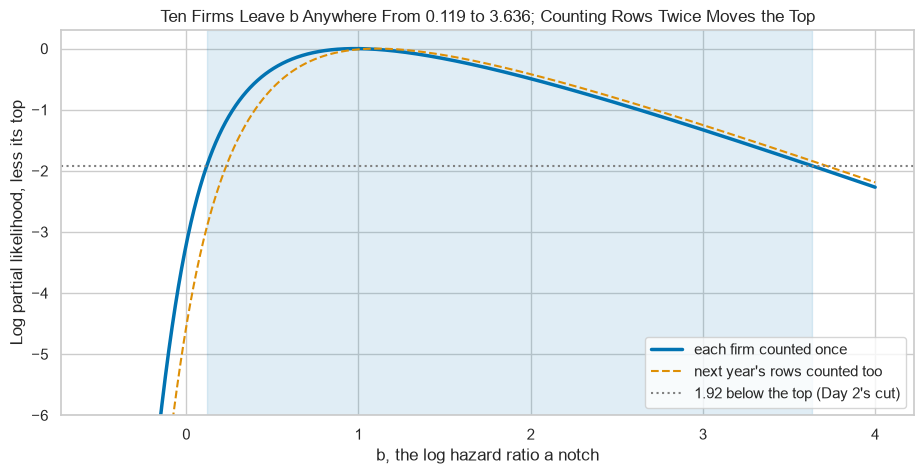

In [22]:
# the two profiles, the 1.92 cut and the range of b it leaves
plt.figure(figsize=(11, 5))
plt.plot(grid, profile - profile.max(), linewidth=2.5, label="each firm counted once")
plt.plot(grid, doubled - doubled.max(), linewidth=1.5, linestyle="--", label="next year's rows counted too")
plt.axhline(-1.92, color="gray", linestyle=":", label="1.92 below the top (Day 2's cut)")
plt.axvspan(inside.min(), inside.max(), color="C0", alpha=0.12)
plt.ylim(-6, 0.3)
plt.xlabel("b, the log hazard ratio a notch")
plt.ylabel("Log partial likelihood, less its top")
plt.title(f"Ten Firms Leave b Anywhere From {inside.min()} to {inside.max()}; Counting Rows Twice Moves the Top")
plt.legend(loc="lower right")
plt.show()

Any entry strictly inside the year counts each firm once; this notebook uses t - 0.5.
Year 3's two defaults are a tie.
`ties=` settles it: **Breslow** (statsmodels' default, and the hand's) shares the full risk set to both; **Efron**, for the second, takes half of the two defaulters' weight out of the sum, as if one had already left.

In [23]:
# entry inside the year, years_since_entry - 0.5, with Breslow's ties and with Efron's
cox_ten = sm.PHReg(ten["years_since_entry"], ten[["rating_score"]], status=ten["default"], entry=ten["years_since_entry"] - 0.5).fit()
cox_ten_efron = sm.PHReg(ten["years_since_entry"], ten[["rating_score"]], status=ten["default"], entry=ten["years_since_entry"] - 0.5, ties="efron").fit()
print(f"PHReg with entry t - 0.5: b = {cox_ten.params[0]:.4f} | the hand: {best_b} | Efron: b = {cox_ten_efron.params[0]:.4f}")

PHReg with entry t - 0.5: b = 0.9808 | the hand: 0.981 | Efron: b = 1.0361


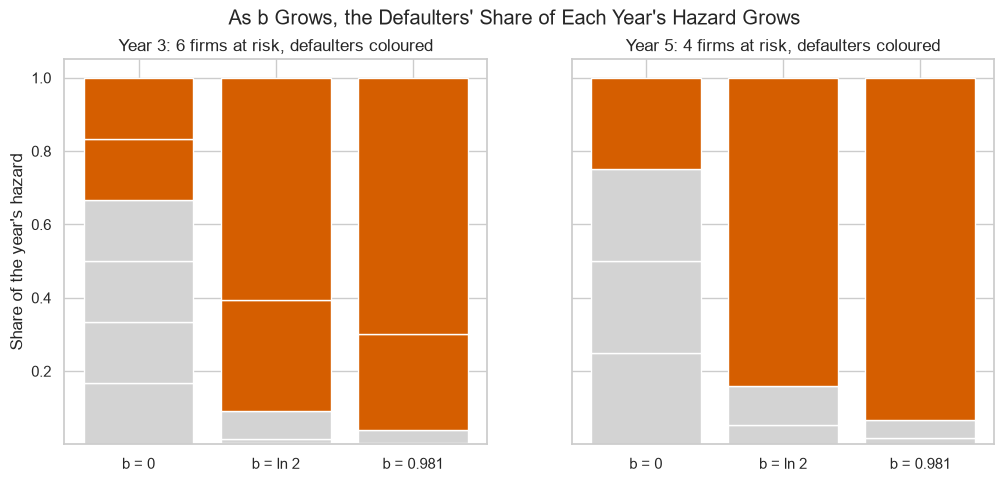

In [24]:
# each firm's share of the year's hazard at three values of b, year 3's six firms and year 5's four, defaulters coloured
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, t in zip(axes, [3, 5]):
    at_risk = ten[ten["years_since_entry"] == t].sort_values("rating_score")
    for i, b in enumerate([0, np.log(2), best_b]):
        share = np.exp(b * at_risk["rating_score"]) / np.exp(b * at_risk["rating_score"]).sum()
        ax.bar(np.full(len(at_risk), i), share, bottom=share.cumsum() - share, color=np.where(at_risk["default"] == 1, "C3", "lightgray"), edgecolor="white")
    ax.set(xticks=range(3), xticklabels=["b = 0", "b = ln 2", f"b = {best_b}"], title=f"Year {t}: {len(at_risk)} firms at risk, defaulters coloured")
axes[0].set_ylabel("Share of the year's hazard")
fig.suptitle("As b Grows, the Defaulters' Share of Each Year's Hazard Grows")
plt.show()

**Ten firms barely pin the slope; the hand check pinned the risk set.**

# The Cox Model on the Cohort

**Predict 2**

Day 3's pooled fit on rating alone gave odds of a default 1.64 times as high a notch.

Q. Fit the Cox model on rating score, leverage and log coverage over all 18,503 firm-years: what hazard ratio a notch? Write down a number.

## One Line on 345 Defaults

In [25]:
# the Cox model on every development firm-year: three inputs, entry inside the year, Efron's ties
COVARIATES = ["rating_score", "leverage", "log_coverage"]
cox_model = sm.PHReg(development["years_since_entry"], development[COVARIATES], status=development["default"],
                     entry=development["years_since_entry"] - 0.5, ties="efron")
cox = cox_model.fit()
cox.summary().tables[1]

,log HR,log HR SE,HR,t,P>|t|,[0.025,0.975]
rating_score,0.391832,0.027605,1.479689,14.194295,9.938089e-46,1.401758,1.561953
leverage,0.151244,0.063140,1.163280,2.395377,1.660326e-02,1.027873,1.316525
log_coverage,-0.646122,0.107731,0.524074,-5.997573,2.002881e-09,0.424319,0.647281


`log HR` is b and `HR` is exp(b); the interval columns are for the hazard ratio.

The p-values: rating score 1e-45, log coverage 2e-09, leverage 0.0166.

In [26]:
# the hazard ratios named with the model's exog_names, and what halving coverage does
hazard_ratios = pd.Series(np.exp(cox.params), index=cox_model.exog_names)
print(hazard_ratios.round(4).to_dict())
print(f"Halving coverage multiplies the fitted hazard by {np.exp(cox.params[2] * np.log(0.5)):.3f}")

# rating score alone in the same model
alone = sm.PHReg(development["years_since_entry"], development[["rating_score"]], status=development["default"],
                 entry=development["years_since_entry"] - 0.5, ties="efron").fit()
print(f"Rating alone: {np.exp(alone.params[0]):.4f} a notch")

{'rating_score': 1.4797, 'leverage': 1.1633, 'log_coverage': 0.5241}
Halving coverage multiplies the fitted hazard by 1.565
Rating alone: 1.6257 a notch


### Interpretation of the Hazard Ratios

One notch down the scale multiplies the fitted hazard by 1.48, leverage and coverage held: an association in this file, never a cause.

1.48 is a multiplier, not a 48 percent chance: a firm-year at 2 percent a year, one notch lower, sits near 2.96.

A turn of leverage multiplies it by 1.16; halving coverage, by 1.57.

Alone, rating's ratio sits near Day 3's odds ratio of 1.64; beside leverage and coverage, which move with it, part of its credit moves to them.

## The Settings That Matter

`strata=` gives each sector a baseline hazard of its own and keeps one set of ratios.

In [27]:
# Breslow's ties against Efron's, and sector as strata
breslow = sm.PHReg(development["years_since_entry"], development[COVARIATES], status=development["default"],
                   entry=development["years_since_entry"] - 0.5, ties="breslow").fit()
strata = sm.PHReg(development["years_since_entry"], development[COVARIATES], status=development["default"],
                  entry=development["years_since_entry"] - 0.5, ties="efron", strata=development["sector"]).fit()
print("Breslow less Efron:", np.round(breslow.params - cox.params, 4), "| in standard errors:", np.round((breslow.params - cox.params) / cox.bse, 2))
print("Sector strata less Efron:", np.round(strata.params - cox.params, 4))

Breslow less Efron: [-0.0109 -0.002   0.035 ] | in standard errors: [-0.39 -0.03  0.33]
Sector strata less Efron: [ 0.0013 -0.0033 -0.0061]


345 defaults on 14 times are heavy ties, yet the two rules part by under 0.4 standard errors.

**Efron's ties and one shared baseline stay; neither setting moves a b by more than 0.04.**

**Predict 3**

The generator has no sector term (`DATA.md`).

Q. Add nine sector indicators against Consumer to the Cox model: how many of the nine p-values fall below 0.05? Write down a number.

## Nine Sectors, None Planted

In [28]:
# nine sector indicators against Consumer (Course 4's pd.get_dummies), beside the three inputs
sectors = pd.get_dummies(development["sector"], dtype=float).drop(columns="Consumer")
sector_model = sm.PHReg(development["years_since_entry"], pd.concat([development[COVARIATES], sectors], axis=1),
                        status=development["default"], entry=development["years_since_entry"] - 0.5, ties="efron")
with_sectors = sector_model.fit()
sector_table = pd.DataFrame({"hazard ratio": np.exp(with_sectors.params), "p-value": with_sectors.pvalues}, index=sector_model.exog_names)
print("Sectors below 0.05:", (sector_table["p-value"].iloc[3:] < 0.05).sum(), "of 9")
sector_table.iloc[3:].round(4)

Sectors below 0.05: 2 of 9


,hazard ratio,p-value
Energy,0.6827,0.1038
Financials,0.6296,0.0414
Health Care,0.6014,0.0426
Industrials,0.7940,0.3016
Materials,0.7713,0.2416
Technology,0.6265,0.0560
Telecom,0.7143,0.1481
Transportation,0.9915,0.9674
Utilities,0.6287,0.0552


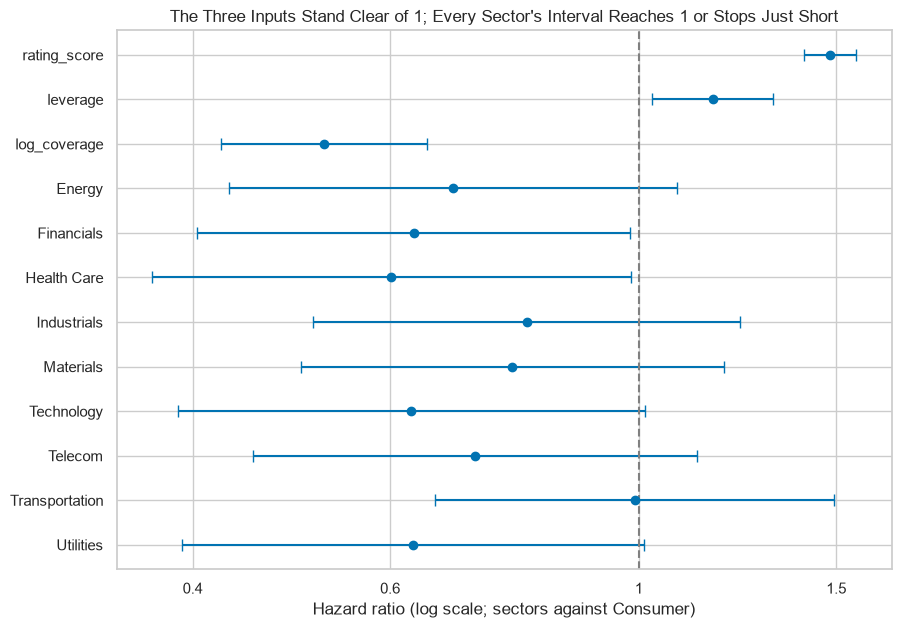

In [29]:
# a forest of hazard ratios on a log axis: the three inputs and the nine sectors against Consumer, 95 percent intervals
interval = np.exp(with_sectors.conf_int())
plt.figure(figsize=(10, 7))
plt.errorbar(sector_table["hazard ratio"], range(12), xerr=[sector_table["hazard ratio"] - interval[:, 0], interval[:, 1] - sector_table["hazard ratio"]], fmt="o", capsize=4)
plt.axvline(1, color="gray", linestyle="--")
plt.xscale("log")
plt.xticks([0.4, 0.6, 1, 1.5], ["0.4", "0.6", "1", "1.5"])
plt.yticks(range(12), sector_table.index)
plt.gca().invert_yaxis()
plt.xlabel("Hazard ratio (log scale; sectors against Consumer)")
plt.title("The Three Inputs Stand Clear of 1; Every Sector's Interval Reaches 1 or Stops Just Short")
plt.show()

Against Consumer is one base of ten.
Making each sector the base in turn gives every pair once: 45 **pairwise contrasts**, many tests at once.
A **volcano plot** sets each contrast's size, the log hazard ratio, against its evidence, -log10 of its p-value: p = 0.05 sits at 1.30, and a point higher up has a smaller p-value.

In [30]:
# each sector as the base in turn: every pair's log hazard ratio and p-value
pairs = {}
for base in sorted(development["sector"].unique()):
    dummies = pd.get_dummies(development["sector"], dtype=float).drop(columns=base)
    model = sm.PHReg(development["years_since_entry"], pd.concat([development[COVARIATES], dummies], axis=1),
                     status=development["default"], entry=development["years_since_entry"] - 0.5, ties="efron")
    fit = model.fit()
    for name, coefficient, p in zip(model.exog_names[3:], fit.params[3:], fit.pvalues[3:]):
        pairs[(min(base, name), max(base, name))] = (coefficient if base < name else -coefficient, p)
# pd.MultiIndex.from_tuples names each row by its pair of sectors
volcano = pd.DataFrame(list(pairs.values()), index=pd.MultiIndex.from_tuples(list(pairs.keys())), columns=["log_hr", "p"])
print("Pairs:", len(volcano), "| below 0.05:", (volcano["p"] < 0.05).sum(), "| 45 x 0.05 =", 45 * 0.05)
volcano[volcano["p"] < 0.05].round(4)

Pairs: 45 | below 0.05: 4 | 45 x 0.05 = 2.25


log_hr       p
Consumer    Financials     -0.4627  0.0414
            Health Care    -0.5086  0.0426
Financials  Transportation  0.4541  0.0416
Health Care Transportation  0.5000  0.0429

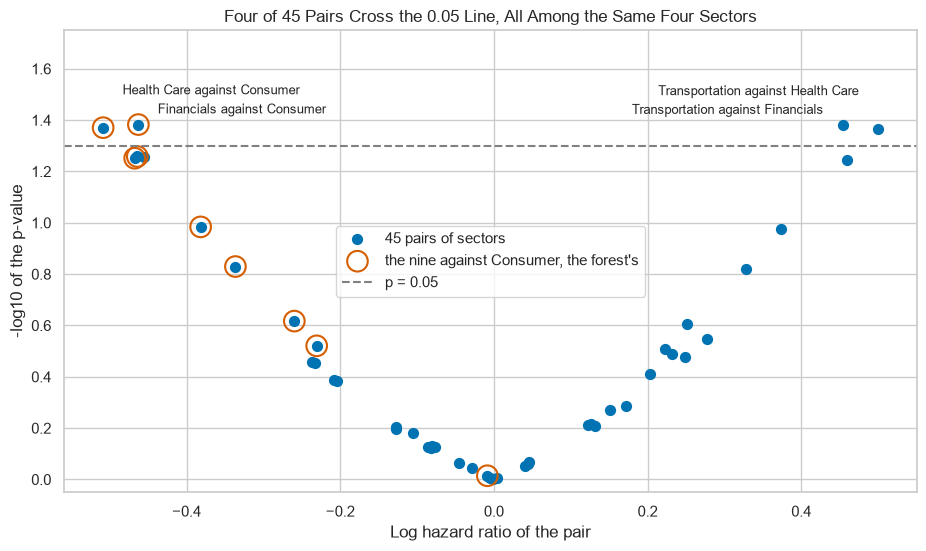

In [31]:
# the volcano: every pair, the 0.05 line, and the nine contrasts against Consumer ringed (np.log10 is the log to base 10)
volcano["minus_log10_p"] = -np.log10(volcano["p"])
against_consumer = ["Consumer" in pair for pair in volcano.index]
plt.figure(figsize=(11, 6))
plt.scatter(volcano["log_hr"], volcano["minus_log10_p"], s=50, color="C0", label="45 pairs of sectors")
plt.scatter(volcano.loc[against_consumer, "log_hr"], volcano.loc[against_consumer, "minus_log10_p"], s=220, facecolors="none", edgecolors="C3", linewidths=1.5, label="the nine against Consumer, the forest's")
plt.axhline(-np.log10(0.05), color="gray", linestyle="--", label="p = 0.05")
for i, pair in enumerate(volcano.index[volcano["p"] < 0.05]):
    left_side = volcano.loc[pair, "log_hr"] < 0
    plt.annotate(f"{pair[1]} against {pair[0]}", (volcano.loc[pair, "log_hr"], volcano.loc[pair, "minus_log10_p"]), xytext=(14 if left_side else -14, 8 if i % 2 == 0 else 24), textcoords="offset points", ha="left" if left_side else "right", fontsize=9)
plt.ylim(-0.05, 1.75)
plt.xlabel("Log hazard ratio of the pair")
plt.ylabel("-log10 of the p-value")
plt.title("Four of 45 Pairs Cross the 0.05 Line, All Among the Same Four Sectors")
plt.legend(loc="center")
plt.show()

The four pair Consumer or Transportation with Financials or Health Care.

2.25 is the count if each test stood alone; the 45 share the same firms, so it is a rough guide.

The **joint test** asks of all nine at once: twice the gain in log-likelihood against chi-squared, one degree of freedom per added term (Day 2's likelihood ratio).

In [32]:
# the joint test of the nine sector indicators
lr = 2 * (with_sectors.llf - cox.llf)
print(f"Likelihood ratio {lr:.2f} on 9 degrees of freedom | p-value {stats.chi2.sf(lr, 9):.4f}")
print("Counted hazard, percent a year:", (100 * development.groupby("sector")["default"].mean()).round(2).to_dict())

Likelihood ratio 11.51 on 9 degrees of freedom | p-value 0.2423
Counted hazard, percent a year: {'Consumer': 2.46, 'Energy': 1.67, 'Financials': 1.72, 'Health Care': 1.51, 'Industrials': 2.15, 'Materials': 2.05, 'Technology': 1.33, 'Telecom': 1.87, 'Transportation': 2.38, 'Utilities': 1.52}


The sectors are labels of these invented firms; Consumer's 2.46 and Transportation's 2.38 percent a year against 1.86 overall are counted rates, nothing more.

**Nine tests at once find something; the joint test, p 0.24, finds nothing beyond chance.**

# The Proportional-Hazards Check

The **proportional-hazards assumption**: a hazard ratio holds at every age.
Then two groups' survival curves, drawn as ln(-ln S) against ln t, run parallel, a gap of ln of their ratio apart.

**Predict 4**

Q. Sketch ln(-ln S) against ln t for Day 4's four entry groups, IG, BB, B and CCC: do they run parallel, cross, or fan out?

## Log-Minus-Log by Entry Group

In [33]:
# each entry group's curve (Day 4's SurvfuncRight), as ln(-ln S) at each time with a default
ORDER = ["IG", "BB", "B", "CCC"]
group_fits = {name: SurvfuncRight(firms.loc[firms["group"] == name, "years"], firms.loc[firms["group"] == name, "defaulted"]) for name in ORDER}
log_minus_log = {name: pd.Series(np.log(-np.log(fit.surv_prob)), index=fit.surv_times) for name, fit in group_fits.items()}

# the gap between neighbouring groups at each time all three have a default
gaps = pd.DataFrame({"BB to B": log_minus_log["B"] - log_minus_log["BB"], "B to CCC": log_minus_log["CCC"] - log_minus_log["B"]}).dropna()
gaps.agg(["min", "max"]).round(4)

,BB to B,B to CCC
min,1.2202,1.0608
max,1.3910,1.4286


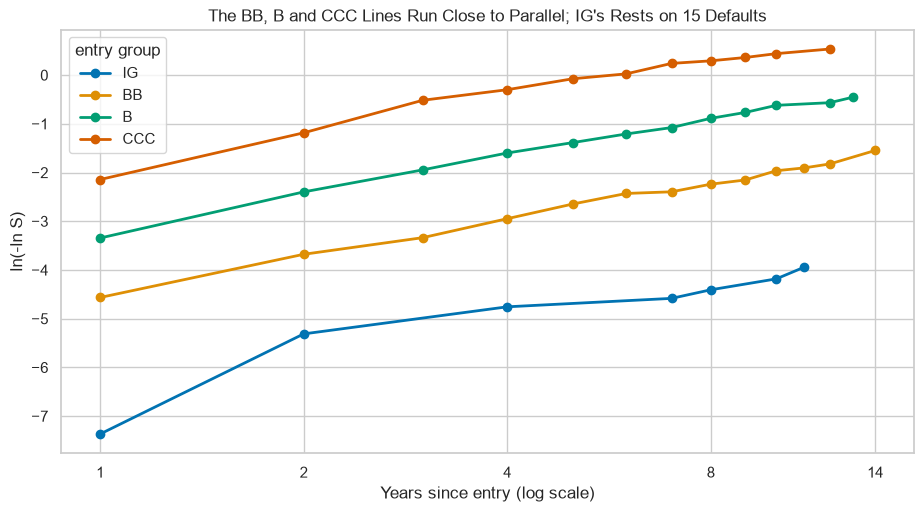

In [34]:
# the log-minus-log plot: four lines over ln t
plt.figure(figsize=(11, 5.5))
for name, line in log_minus_log.items():
    plt.plot(np.log(line.index), line, marker="o", linewidth=2, label=name)
plt.xticks(np.log([1, 2, 4, 8, 14]), ["1", "2", "4", "8", "14"])
plt.xlabel("Years since entry (log scale)")
plt.ylabel("ln(-ln S)")
plt.title("The BB, B and CCC Lines Run Close to Parallel; IG's Rests on 15 Defaults")
plt.legend(title="entry group")
plt.show()

Each gap moves within about 0.2 (BB to B) and 0.4 (B to CCC) across the years: no crossing and no fan.

## Early Years Against Later

A second check: fit the Cox model on years 1 to 4 since entry and on 5 to 14 apart, and compare.

In [35]:
# the Cox model on the early and the later years since entry, and each coefficient's gap in standard errors
fits = {}
for label, low, high in [("years 1 to 4", 1, 4), ("years 5 to 14", 5, 14)]:
    part = development[development["years_since_entry"].between(low, high)]
    fits[label] = sm.PHReg(part["years_since_entry"], part[COVARIATES], status=part["default"], entry=part["years_since_entry"] - 0.5, ties="efron").fit()
    print(label, "| defaults:", part["default"].sum(), "| b:", np.round(fits[label].params, 4))
early, later = fits.values()
print("Gap in standard errors:", np.round(np.abs(early.params - later.params) / np.sqrt(early.bse ** 2 + later.bse ** 2), 2))

years 1 to 4 | defaults: 241 | b: [ 0.3931  0.1695 -0.6416]
years 5 to 14 | defaults: 104 | b: [ 0.3853  0.1229 -0.6568]
Gap in standard errors: [0.14 0.36 0.07]


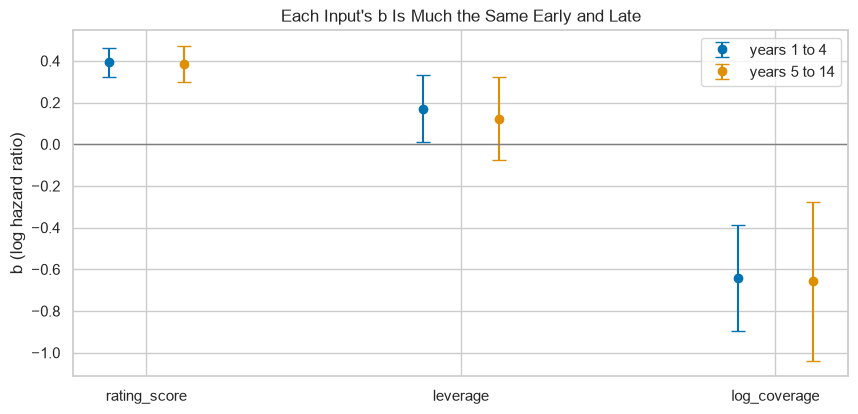

In [36]:
# each coefficient, early against later, with 1.96 standard-error whiskers
plt.figure(figsize=(10, 4.5))
for shift, (label, fit) in zip([-0.12, 0.12], fits.items()):
    plt.errorbar(np.arange(3) + shift, fit.params, yerr=1.96 * fit.bse, fmt="o", capsize=5, label=label)
plt.axhline(0, color="gray", linewidth=1)
plt.xticks(range(3), COVARIATES)
plt.ylabel("b (log hazard ratio)")
plt.title("Each Input's b Is Much the Same Early and Late")
plt.legend()
plt.show()

**One ratio per input holds across ages here, as the generator built it.**

# The Discrete-Time Hazard

## The Logistic Hazard

The **discrete-time hazard** is the chance of a default in a year at risk.
Day 3's pooled logistic fit on rating score was one; here it takes the four features.

In [37]:
# the logistic hazard on the four features, every development firm-year
logit = sm.Logit(development["default"], sm.add_constant(development[FEATURES])).fit(disp=0)

# the odds ratio a notch, what one notch does to a 2 percent yearly chance, and the share of small fitted chances
odds_ratio = np.exp(logit.params["rating_score"])
odds = 0.02 / 0.98 * odds_ratio
print(f"Odds ratio a notch: {odds_ratio:.4f} | a 2 percent year becomes {100 * odds / (1 + odds):.2f} percent, {odds / (1 + odds) / 0.02:.4f} times as high")
print(f"Firm-years fitted under 5 percent: {100 * (logit.predict() < 0.05).mean():.1f} percent | in-sample AUC: {roc_auc_score(development['default'], logit.predict()):.4f}")
logit.summary2().tables[1]

Odds ratio a notch: 1.4856 | a 2 percent year becomes 2.94 percent, 1.4713 times as high
Firm-years fitted under 5 percent: 89.4 percent | in-sample AUC: 0.8771


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
const,-9.132008,0.485422,-18.812523,5.963066e-79,-10.083417,-8.180599
rating_score,0.395830,0.028547,13.865782,1.021079e-43,0.339879,0.451782
leverage,0.154812,0.066340,2.333617,1.961577e-02,0.024788,0.284835
log_coverage,-0.673951,0.113130,-5.957296,2.564459e-09,-0.895682,-0.452219
early_years,0.339279,0.113132,2.998959,2.709035e-03,0.117544,0.561015


exp(b) here is an **odds ratio** of a default in that year; where the yearly chance is small, as in nine firm-years of ten here, it reads close to a hazard ratio, and 1.4856 sits beside the Cox ratio's 1.4797.

## Beside the Generator's Coefficients

`DATA.md` plants 0.38 on rating score, 0.25 on leverage, -0.40 on log coverage and 0.30 on the early years.
**Study-year indicators** give each study year a constant of its own.

In [38]:
# the same fit with 13 study-year indicators, beside the planted values, and the joint test of the 13
years = pd.get_dummies(development["study_year"], prefix="year", dtype=float).drop(columns="year_1")
logit_years = sm.Logit(development["default"], pd.concat([sm.add_constant(development[FEATURES]), years], axis=1)).fit(disp=0)
planted = pd.Series({"rating_score": 0.38, "leverage": 0.25, "log_coverage": -0.40, "early_years": 0.30})
beside = pd.DataFrame({"planted": planted, "no indicators": logit.params[FEATURES], "with indicators": logit_years.params[FEATURES], "gap in se": (logit_years.params[FEATURES] - planted) / logit_years.bse[FEATURES]})
lr_years = 2 * (logit_years.llf - logit.llf)
print(f"Joint test of the 13 indicators: {lr_years:.2f} on 13 degrees of freedom | p-value {stats.chi2.sf(lr_years, 13):.4f}")
beside.round(4)

Joint test of the 13 indicators: 27.28 on 13 degrees of freedom | p-value 0.0114


,planted,no indicators,with indicators,gap in se
rating_score,0.38,0.3958,0.4003,0.7082
leverage,0.25,0.1548,0.1629,-1.3063
log_coverage,-0.40,-0.6740,-0.6586,-2.2811
early_years,0.30,0.3393,0.2975,-0.0212


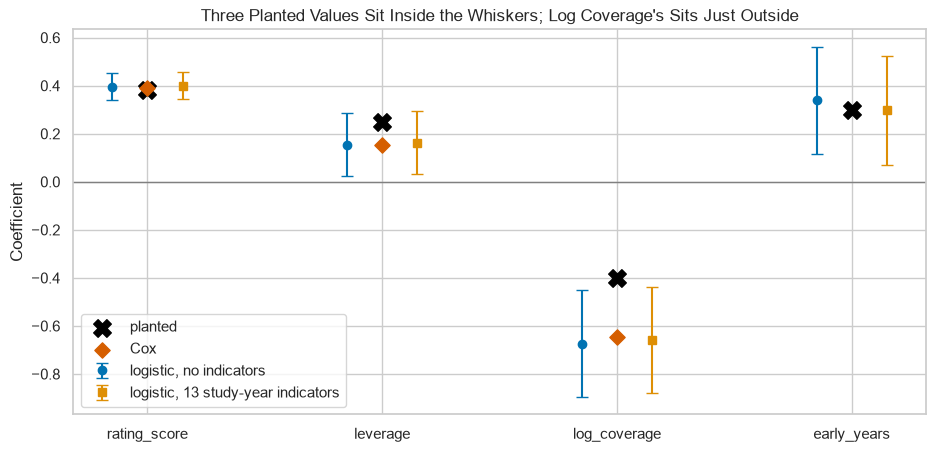

In [39]:
# the planted values as crosses, the two logistic fits with 1.96 standard-error whiskers, and the Cox b's
plt.figure(figsize=(11, 5))
x = np.arange(4)
plt.scatter(x, planted, marker="X", s=160, color="black", zorder=3, label="planted")
plt.errorbar(x - 0.15, logit.params[FEATURES], yerr=1.96 * logit.bse[FEATURES], fmt="o", capsize=4, label="logistic, no indicators")
plt.errorbar(x + 0.15, logit_years.params[FEATURES], yerr=1.96 * logit_years.bse[FEATURES], fmt="s", capsize=4, label="logistic, 13 study-year indicators")
plt.scatter(np.arange(3), cox.params, marker="D", s=60, color="C3", zorder=3, label="Cox")
plt.axhline(0, color="gray", linewidth=1)
plt.xticks(x, FEATURES)
plt.ylabel("Coefficient")
plt.title("Three Planted Values Sit Inside the Whiskers; Log Coverage's Sits Just Outside")
plt.legend(loc="lower left")
plt.show()

Log coverage sits about two standard errors out: sampling, as `DATA.md` records for the development years.

## From Yearly Hazards to Survival

Day 4's running product turns yearly hazards into survival: S(t) is the product of (1 - h) over the years to t.

In [40]:
# an invented firm held at one score, leverage and coverage: its yearly hazards, then the running product
def held_survival(score, leverage, coverage, n_years=10):
    """Share free of default after each year for an invented firm held at these values."""
    year = np.arange(1, n_years + 1)
    rows = pd.DataFrame({"const": 1.0, "rating_score": score, "leverage": leverage, "log_coverage": np.log(coverage), "early_years": ((year >= 2) & (year <= 4)).astype(int)})
    return pd.Series(np.cumprod(1 - logit.predict(rows).to_numpy()), index=year)

# typical entrants: the median leverage and coverage of the firms entering at scores 9 (BBB), 12 (BB) and 15 (B)
entrants = development[development["years_since_entry"] == 1]
typical = entrants.groupby("rating_score")[["leverage", "coverage"]].median().loc[[9, 12, 15]]
typical["past 10 years"] = [held_survival(score, row["leverage"], row["coverage"]).loc[10] for score, row in typical.iterrows()]
typical.round(4)

,leverage,coverage,past 10 years
rating_score,,,
9,3.745,6.455,0.9785
12,4.600,4.980,0.9082
15,5.550,3.750,0.6470


In [41]:
# every entrant held at its entry values for 14 years, averaged by entry group, beside Day 4's Kaplan-Meier
year = np.arange(1, 15)
base = logit.params["const"] + entrants[["rating_score", "leverage", "log_coverage"]].to_numpy() @ logit.params[["rating_score", "leverage", "log_coverage"]].to_numpy()
hazard = 1 / (1 + np.exp(-(base[:, None] + logit.params["early_years"] * ((year >= 2) & (year <= 4)))))
held = pd.DataFrame(np.cumprod(1 - hazard, axis=1), columns=year).groupby(entrants["firm_id"].map(firms["group"]).to_numpy()).mean()
pd.DataFrame({"held at entry": held[10], "Kaplan-Meier": [group_fits[name].surv_prob[group_fits[name].surv_times <= 10][-1] for name in held.index]}).loc[ORDER].round(4)

,held at entry,Kaplan-Meier
IG,0.9836,0.9849
BB,0.8936,0.8690
B,0.6237,0.5842
CCC,0.2613,0.2117


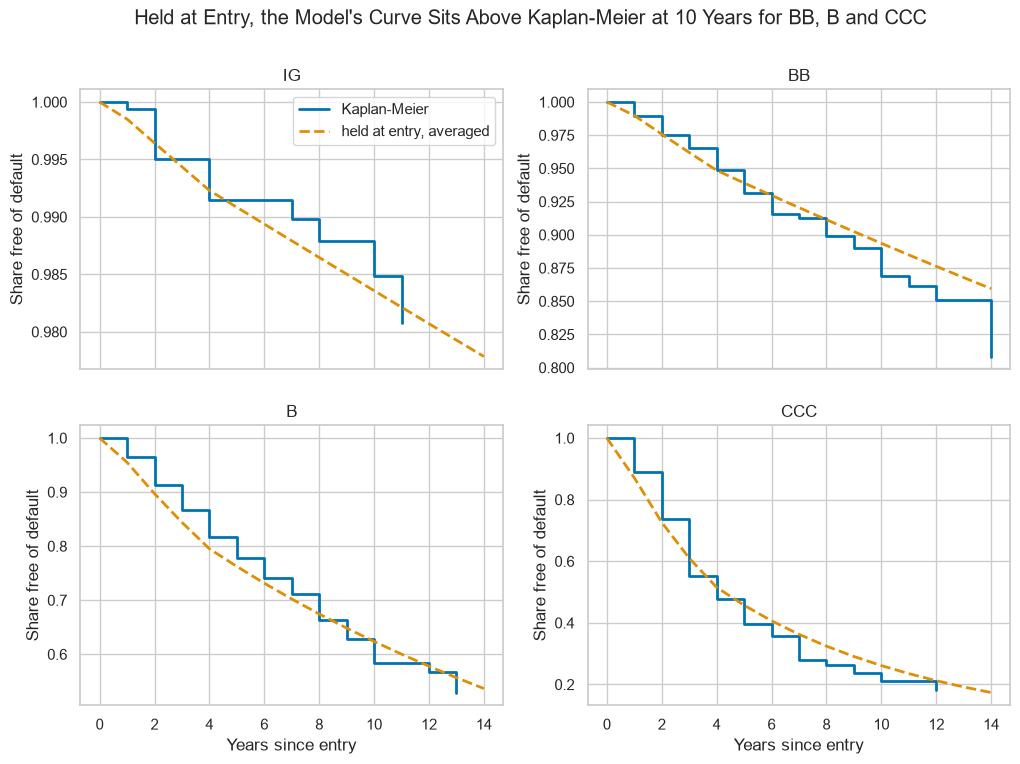

In [42]:
# small multiples: each group's Kaplan-Meier steps against its entrants' averaged curve held at entry
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for ax, name in zip(axes.flat, ORDER):
    ax.step(np.append(0, group_fits[name].surv_times), np.append(1, group_fits[name].surv_prob), where="post", linewidth=2, label="Kaplan-Meier")
    ax.plot(np.append(0, year), np.append(1, held.loc[name]), linestyle="--", linewidth=2, label="held at entry, averaged")
    ax.set(title=name, ylabel="Share free of default")
axes[1, 0].set_xlabel("Years since entry")
axes[1, 1].set_xlabel("Years since entry")
axes[0, 0].legend()
fig.suptitle("Held at Entry, the Model's Curve Sits Above Kaplan-Meier at 10 Years for BB, B and CCC")
plt.show()

Firms in the file step down the scale more often than up (1,213 steps against 908), so over a long watch a firm held at its entry values reads too safe.

## Your Turn: Any Firm

In [43]:
# an invented firm's curve over 10 years, the 5- and 10-year points marked
def draw_firm(score=12, leverage=4.6, coverage=5.0):
    curve = 100 * held_survival(score, leverage, coverage)
    plt.figure(figsize=(11, 4.5))
    plt.step(np.append(0, curve.index), np.append(100, curve), where="post", linewidth=2)
    plt.scatter([5, 10], curve.loc[[5, 10]], color="C3", s=70, zorder=3)
    plt.ylim(0, 101)
    plt.xlabel("Years held")
    plt.ylabel("Share free of default (percent)")
    plt.title(f"Score {score}, Leverage {leverage}, Coverage {coverage}: Free of Default {curve.loc[5]:.1f} Percent Past 5 Years, {curve.loc[10]:.1f} Past 10")
    plt.show()

In [44]:
# your turn: move the invented firm's score, leverage and coverage
interact(draw_firm, score=(1, 18, 1), leverage=(0.5, 10.0, 0.1), coverage=(0.5, 20.0, 0.1));

interactive(children=(IntSlider(value=12, description='score', max=18, min=1), FloatSlider(value=4.6, descript…

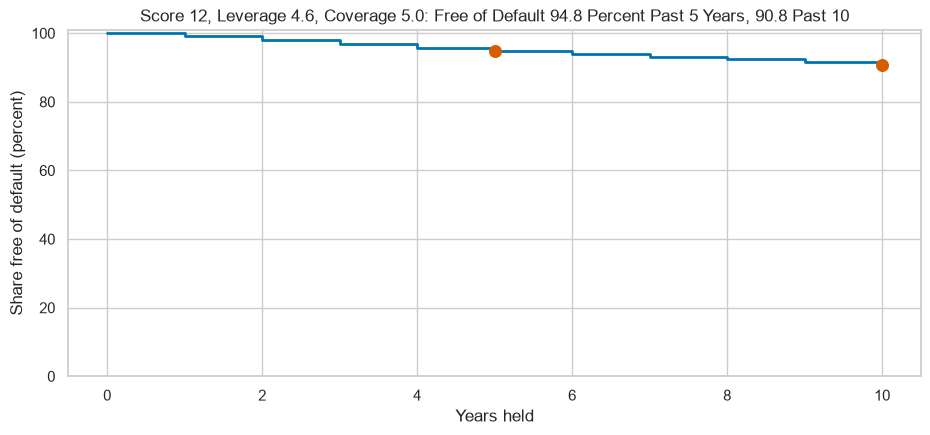

In [45]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_firm(score=12, leverage=4.6, coverage=5.0)

**One fit gives every firm-year a hazard and every firm a curve; a firm held fixed reads too safe.**

# Model Performance Evaluation

The colleague's question: fitted only on the study years before each year, would the model have ranked and sized that year's defaults?
This is Course 4's Day 11 walk-forward with expanding windows: train on study years 1 to k - 1, test on year k.

## The Walk-Forward by Study Year

In [46]:
# test years 8 to 14: each fitted on every earlier study year, then scored on its own year
scored = []
for test_year in range(8, 15):
    train = development[development["study_year"] < test_year]
    test = development[development["study_year"] == test_year].copy()
    fit = sm.Logit(train["default"], sm.add_constant(train[FEATURES])).fit(disp=0)
    test["fitted"] = fit.predict(sm.add_constant(test[FEATURES]))
    scored.append(test)
    print(f"test year {test_year}: trained on study years 1 to {test_year - 1} | {len(train):,} rows, {train['default'].sum()} defaults")
scored = pd.concat(scored)

test year 8: trained on study years 1 to 7 | 5,889 rows, 117 defaults
test year 9: trained on study years 1 to 8 | 7,361 rows, 140 defaults
test year 10: trained on study years 1 to 9 | 8,981 rows, 172 defaults
test year 11: trained on study years 1 to 10 | 10,705 rows, 217 defaults
test year 12: trained on study years 1 to 11 | 12,497 rows, 237 defaults
test year 13: trained on study years 1 to 12 | 14,394 rows, 260 defaults
test year 14: trained on study years 1 to 13 | 16,402 rows, 300 defaults


**Predict 5**

Day 3 found study years 10, 11 and 12 outside its independent band, with a pooled fit on rating alone over all fourteen years.

Q. With leverage and coverage added, and each test year scored by a model fitted only on the years before it, sketch two lines over test years 8 to 14: the AUC, and the counted defaults over the model's count. Does the gap Day 3 found close?

## Ranking and Level, Year by Year

In [47]:
# each test year: the AUC, the counted defaults against the model's count, and Day 3's independent band in sd
rows = []
for test_year, test in scored.groupby("study_year"):
    sd = np.sqrt((test["fitted"] * (1 - test["fitted"])).sum())
    rows.append({"AUC": roc_auc_score(test["default"], test["fitted"]), "counted": test["default"].sum(), "model count": test["fitted"].sum(), "sd": sd})
walk = pd.DataFrame(rows, index=range(8, 15))
walk["counted over model"] = walk["counted"] / walk["model count"]
walk["gap in sd"] = (walk["counted"] - walk["model count"]) / walk["sd"]
print(f"Mean AUC (walk-forward): {walk['AUC'].mean():.4f} | counted {walk['counted'].sum()} against the model's {walk['model count'].sum():.1f}")
walk.round(4)

Mean AUC (walk-forward): 0.8772 | counted 228 against the model's 241.8


,AUC,counted,model count,sd,counted over model,gap in sd
8,0.8416,23,25.7536,4.8414,0.8931,-0.5687
9,0.8806,32,28.8751,5.0911,1.1082,0.6138
10,0.8457,45,29.2656,5.1576,1.5376,3.0507
11,0.8944,20,33.1171,5.5066,0.6039,-2.3821
12,0.9168,23,36.7300,5.7800,0.6262,-2.3754
13,0.8834,40,39.8648,6.0174,1.0034,0.0225
14,0.8776,45,48.2361,6.5855,0.9329,-0.4914


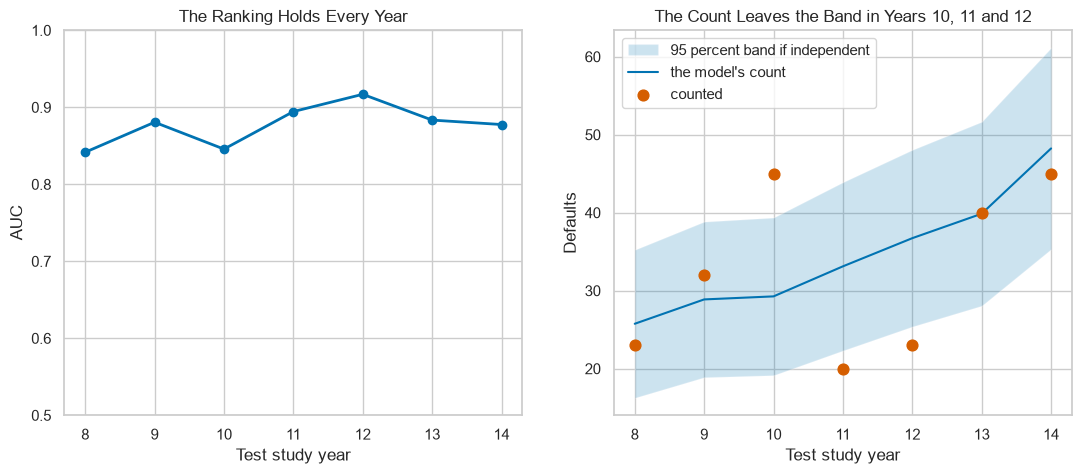

In [48]:
# left: the AUC by test year; right: counted against the model's count inside Day 3's band
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5))
left.plot(walk.index, walk["AUC"], marker="o", linewidth=2)
left.set(ylim=(0.5, 1), xlabel="Test study year", ylabel="AUC", title="The Ranking Holds Every Year")
right.fill_between(walk.index, walk["model count"] - 1.96 * walk["sd"], walk["model count"] + 1.96 * walk["sd"], alpha=0.2, label="95 percent band if independent")
right.plot(walk.index, walk["model count"], label="the model's count")
right.scatter(walk.index, walk["counted"], color="C3", s=60, zorder=3, label="counted")
right.set(xlabel="Test study year", ylabel="Defaults", title="The Count Leaves the Band in Years 10, 11 and 12")
right.legend()
plt.show()

The AUC stays between 0.84 and 0.92 in every test year.

The count does not hold: 1.54 times the model's count in year 10, 0.60 and 0.63 in years 11 and 12, each outside the band.

The model ranks firms inside a year; the shock `DATA.md` draws once a study year and shares across every firm has no column in it, so the year's level is outside its reach.

A hazard model gives every firm-year its own hazard from that year's rating, leverage and coverage; fitted on earlier study years it ranks a later year's firms well, but it cannot see what a whole year shares.

## Calibration by Decile

In [49]:
# the seven test years pooled and cut into ten groups by the model's default probability (Course 1's pd.qcut)
scored["decile"] = pd.qcut(scored["fitted"], 10, labels=range(1, 11))
deciles = scored.groupby("decile", observed=True).agg(firm_years=("default", "size"), counted=("default", "sum"), fitted=("fitted", "mean"), counted_rate=("default", "mean"))
deciles[["fitted", "counted_rate"]] = 100 * deciles[["fitted", "counted_rate"]]
print("Top decile's share of the defaults:", round(deciles["counted"].iloc[-1] / deciles["counted"].sum(), 4), "| bottom five deciles' defaults:", deciles["counted"].iloc[:5].sum())
deciles.round(2)

Top decile's share of the defaults: 0.5395 | bottom five deciles' defaults: 10


,firm_years,counted,fitted,counted_rate
decile,,,,
1,1262,0,0.01,0.00
2,1261,1,0.05,0.08
3,1261,1,0.12,0.08
4,1262,2,0.22,0.16
5,1261,6,0.37,0.48
6,1261,5,0.61,0.40
7,1262,15,1.01,1.19
8,1261,24,1.83,1.90
9,1261,51,3.74,4.04


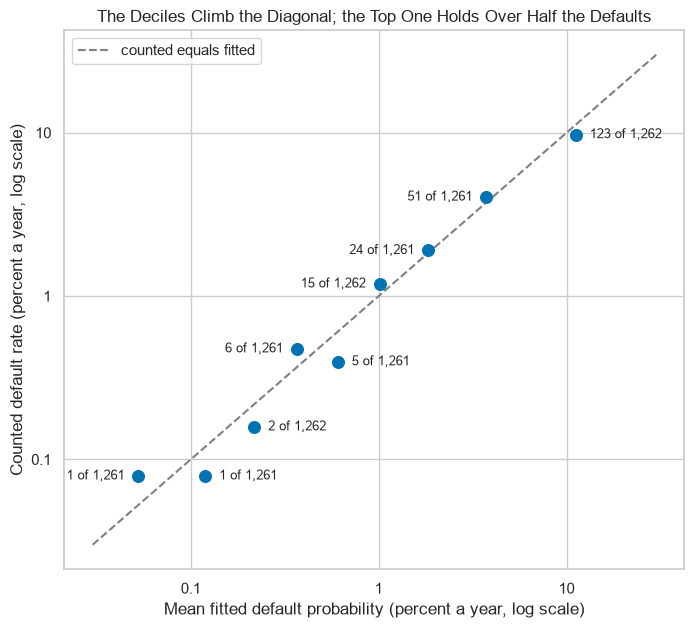

In [50]:
# the reliability diagram by decile on log axes (Course 4's Day 8), each point labelled with its defaults
plt.figure(figsize=(8, 7))
with_defaults = deciles[deciles["counted"] > 0]
plt.scatter(with_defaults["fitted"], with_defaults["counted_rate"], s=70, zorder=3)
for decile, row in with_defaults.iterrows():
    above = row["counted_rate"] > row["fitted"]
    plt.annotate(f"{int(row['counted'])} of {int(row['firm_years']):,}", (row["fitted"], row["counted_rate"]), xytext=(-10 if above else 10, 0), textcoords="offset points", ha="right" if above else "left", va="center", fontsize=9)
plt.plot([0.03, 30], [0.03, 30], color="gray", linestyle="--", label="counted equals fitted")
plt.xscale("log")
plt.yscale("log")
plt.xticks([0.1, 1, 10], ["0.1", "1", "10"])
plt.yticks([0.1, 1, 10], ["0.1", "1", "10"])
plt.xlabel("Mean fitted default probability (percent a year, log scale)")
plt.ylabel("Counted default rate (percent a year, log scale)")
plt.title("The Deciles Climb the Diagonal; the Top One Holds Over Half the Defaults")
plt.legend()
plt.show()

The top decile holds 123 of the 228 defaults; it was fitted at 11.21 percent and counted 9.75.

The bottom five deciles hold 10, and the lowest counted none, so it has no point on log axes.

**It ranks firms; it cannot see the year.**

# Model Performance Comparison

## Three Rankers

Two more rankers, walked forward the same way: a logistic fit on rating alone, refitted each year (Day 3's form, never its fourteen-year fit), and the Cox model on three inputs, ranking by b x.

In [51]:
# the three rankers, each fitted on the years before each test year
for test_year in range(8, 15):
    train = development[development["study_year"] < test_year]
    rows = scored["study_year"] == test_year
    rating_fit = sm.Logit(train["default"], sm.add_constant(train[["rating_score"]])).fit(disp=0)
    scored.loc[rows, "rating_only"] = rating_fit.predict(sm.add_constant(scored.loc[rows, ["rating_score"]]))
    cox_fit = sm.PHReg(train["years_since_entry"], train[COVARIATES], status=train["default"], entry=train["years_since_entry"] - 0.5, ties="efron").fit()
    scored.loc[rows, "cox"] = scored.loc[rows, COVARIATES].to_numpy() @ cox_fit.params
rankers = pd.DataFrame({name: [roc_auc_score(test["default"], test[column]) for _, test in scored.groupby("study_year")] for name, column in [("rating only", "rating_only"), ("Cox, three inputs", "cox"), ("logistic, four inputs", "fitted")]}, index=range(8, 15))
rankers.round(4)

,rating only,"Cox, three inputs","logistic, four inputs"
8,0.8119,0.8359,0.8416
9,0.8493,0.8759,0.8806
10,0.8359,0.8445,0.8457
11,0.8739,0.8901,0.8944
12,0.9087,0.9178,0.9168
13,0.8838,0.8889,0.8834
14,0.8621,0.8786,0.8776


In [52]:
# means, the four inputs' gain over rating only, rating only's yearly range, and the Brier score on the pooled test years
gain = rankers["logistic, four inputs"] - rankers["rating only"]
print("Mean AUC:", rankers.mean().round(4).to_dict())
print(f"Gain {gain.mean():.4f}, ahead in {(gain > 0).sum()} of 7 | rating only's range {rankers['rating only'].max() - rankers['rating only'].min():.4f}")
print(f"Brier: four inputs {brier_score_loss(scored['default'], scored['fitted']):.6f} | rating only {brier_score_loss(scored['default'], scored['rating_only']):.6f}")

Mean AUC: {'rating only': 0.8608, 'Cox, three inputs': 0.876, 'logistic, four inputs': 0.8772}
Gain 0.0163, ahead in 6 of 7 | rating only's range 0.0969
Brier: four inputs 0.016551 | rating only 0.016780


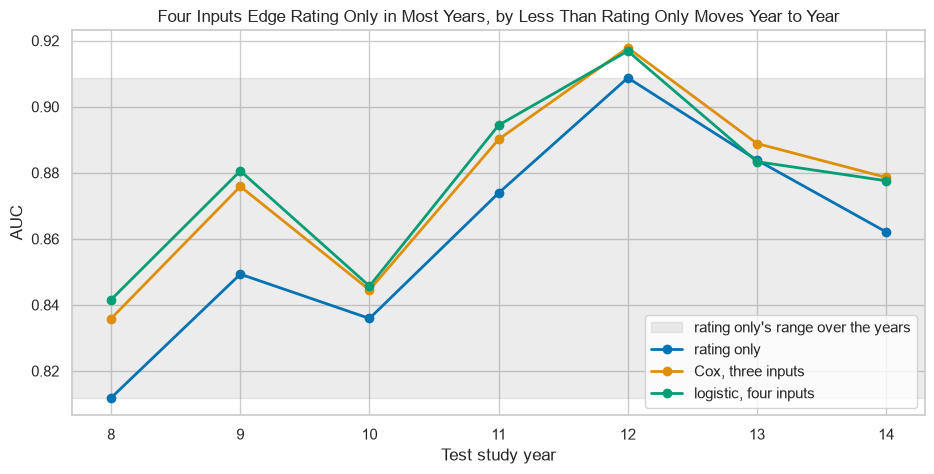

In [53]:
# the AUC by test year for the three, rating only's range across the years shaded
plt.figure(figsize=(11, 5))
plt.axhspan(rankers["rating only"].min(), rankers["rating only"].max(), color="gray", alpha=0.15, label="rating only's range over the years")
for name in rankers.columns:
    plt.plot(rankers.index, rankers[name], marker="o", linewidth=2, label=name)
plt.xlabel("Test study year")
plt.ylabel("AUC")
plt.title("Four Inputs Edge Rating Only in Most Years, by Less Than Rating Only Moves Year to Year")
plt.legend(loc="lower right")
plt.show()

Four inputs rank ahead of rating only in 6 of 7 test years, by 0.0163 on average, inside rating only's own spread of 0.0969 across the years.

The Brier score (Course 5's Day 13) is lower for four inputs, 0.016551 against 0.016780.

**The capstone chooses between them by a rule written down before the held-out years are opened.**

> STORY: David Cox wrote down the full likelihood for censored survival data with explanatory variables and was "horrified at it".
> He told Nancy Reid he was stuck "for the best part of five years or maybe even longer", until he saw that the thing to do was to keep only the part of the likelihood that carried the regression coefficients.
> "It occurred to me while I had a high temperature and was in bed with flu", and when he felt better he worked the argument out again.
> Sources: N. Reid, "A Conversation with Sir David Cox", Statistical Science 9 (3), 1994, pages 439 to 455 (the quotes on page 449), https://doi.org/10.1214/ss/1177010394; D. R. Cox, "Regression Models and Life-Tables", Journal of the Royal Statistical Society Series B 34 (2), 1972, pages 187 to 202, https://doi.org/10.1111/j.2517-6161.1972.tb00899.x

# Insights and Conclusion

An entry inside the year counts each firm once in its risk set.

One notch down the scale went with a fitted hazard 1.48 times as high, leverage and coverage held.

Two of nine sector indicators fell below 0.05 with no sector term planted; the joint test gave p 0.24.

The ratios held across ages, and the logistic hazard landed near the planted values but for log coverage.

Walk-forward, the AUC ran 0.84 to 0.92 while the count ran 1.54 and 0.60 times the model's in years 10 and 11.

**A hazard model sorts firms; the year they share is outside its columns.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Read firm-years as intervals on the years-since-entry clock and run the cut test by study year.
* Work a Cox partial likelihood by hand and match it with `sm.PHReg`, entry included.
* Read hazard ratios, and set `ties` and `strata`.
* Test indicators one at a time and jointly, and read a volcano plot.
* Check proportional hazards with log-minus-log curves and with early and later fits.
* Fit a discrete-time hazard and turn its yearly hazards into survival.
* Score a hazard model walk-forward by study year on ranking, level and calibration, and compare models.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [54]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Two Notches**

Q. From `cox`, store the hazard ratio for two notches down the scale, leverage and coverage held, in `ex1_two_notches`.

In [55]:
# exp(2 b): two notches multiply the fitted hazard by the one-notch ratio twice
ex1_two_notches = np.exp(2 * cox.params[0])
print(f"Two notches: {ex1_two_notches:.4f} | one notch, squared: {np.exp(cox.params[0]) ** 2:.4f}")

Two notches: 2.1895 | one notch, squared: 2.1895


Ratios multiply: two notches are 1.48 times 1.48, never 2 times 48 percent.

In [56]:
check("Exercise 1 the Cox ratio for two notches", ex1_two_notches, 2.189480162242361)

Exercise 1 the Cox ratio for two notches: correct


### Exercise 2

**An Invented Firm**

Q. An invented firm scores 13, with leverage 4.5 and coverage 3.0, held at those values for 5 years. With `held_survival`, store its chance of a default within 5 years in `ex2_default_5`, as a fraction.

In [57]:
# the invented firm held at score 13, leverage 4.5 and coverage 3.0 for 5 years, from the lesson's held_survival
firm_13 = held_survival(13, 4.5, 3.0, n_years=5)
ex2_default_5 = 1 - firm_13.loc[5]
print(f"Free of default past 5 years: {firm_13.loc[5]:.4f} | default within 5 years: {100 * ex2_default_5:.2f} percent")

Free of default past 5 years: 0.8966 | default within 5 years: 10.34 percent


The firm is held at its values for all 5 years, so the lesson's caution holds: a real firm drifts.

In [58]:
check("Exercise 2 default within 5 years", ex2_default_5, 0.10343338179337491)

Exercise 2 default within 5 years: correct


### Exercise 3

**Calibration as a Function**

Q. Write `calibration_by_decile(fitted, event, n_groups=10)`, with a one-line docstring, which returns each group's firm-years, defaults, mean fitted probability and counted rate. Run it on `logit`'s in-sample fitted probabilities and store the top group's counted rate, as a fraction, in `ex3_top_observed`.

In [59]:
# the lesson's calibration by decile as a function
def calibration_by_decile(fitted, event, n_groups=10):
    """Firm-years, defaults, mean fitted probability and counted rate in each group of fitted probabilities."""
    groups = pd.qcut(fitted, n_groups, labels=range(1, n_groups + 1))
    rows = pd.DataFrame({"fitted": fitted, "event": event})
    return rows.groupby(groups, observed=True).agg(firm_years=("event", "size"), defaults=("event", "sum"),
                                                   fitted=("fitted", "mean"), counted_rate=("event", "mean"))

# logit's in-sample fitted probabilities, every development firm-year
in_sample = calibration_by_decile(logit.predict(sm.add_constant(development[FEATURES])), development["default"])
ex3_top_observed = in_sample["counted_rate"].iloc[-1]
print(f"Top group, in-sample: counted {ex3_top_observed:.4f} against fitted {in_sample['fitted'].iloc[-1]:.4f}")

Top group, in-sample: counted 0.1059 against fitted 0.1099


In-sample the top group's fitted and counted rates sit close: the model was fitted on these rows, unlike the walk-forward's test years.

In [60]:
check("Exercise 3 the top decile's counted rate, in-sample", ex3_top_observed, 0.10588870880605078)

Exercise 3 the top decile's counted rate, in-sample: correct


### Exercise 4

**A Rolling Window**

Q. Rerun the walk-forward with each test year fitted on only the five study years before it (Course 4's Day 11 rolling window). Store the mean AUC over test years 8 to 14 in `ex4_rolling_auc`.

In [61]:
# the walk-forward with each test year fitted on only the five study years before it
rolling_auc = []
for test_year in range(8, 15):
    train = development[development["study_year"].between(test_year - 5, test_year - 1)]
    test = development[development["study_year"] == test_year]
    fit = sm.Logit(train["default"], sm.add_constant(train[FEATURES])).fit(disp=0)
    rolling_auc.append(roc_auc_score(test["default"], fit.predict(sm.add_constant(test[FEATURES]))))
    print(f"test year {test_year}: trained on study years {test_year - 5} to {test_year - 1} | AUC {rolling_auc[-1]:.4f}")
ex4_rolling_auc = np.mean(rolling_auc)
print(f"Mean AUC, five-year window: {ex4_rolling_auc:.4f} | every earlier year: {walk['AUC'].mean():.4f}")

test year 8: trained on study years 3 to 7 | AUC 0.8421
test year 9: trained on study years 4 to 8 | AUC 0.8808
test year 10: trained on study years 5 to 9 | AUC 0.8452
test year 11: trained on study years 6 to 10 | AUC 0.8933
test year 12: trained on study years 7 to 11 | AUC 0.9161
test year 13: trained on study years 8 to 12 | AUC 0.8811
test year 14: trained on study years 9 to 13 | AUC 0.8769
Mean AUC, five-year window: 0.8765 | every earlier year: 0.8772


The shorter window ranks about as well: the ranking rests on inputs whose ratios held across the years.

In [62]:
check("Exercise 4 mean AUC on a five-year window", ex4_rolling_auc, 0.8765057276150064)

Exercise 4 mean AUC on a five-year window: correct


### Exercise 5: AI check

**Years Watched**

You asked an AI assistant for a function that adds features to firm-year rows.
This came back.
Test it against its own docstring, then find the one bug.

In [63]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def add_features(rows):
    """Add log_coverage, early_years and years_watched (the years the firm has been watched so far) to firm-year rows."""
    out = rows.copy()
    out["log_coverage"] = np.log(out["coverage"])
    out["early_years"] = out["years_since_entry"].between(2, 4).astype(int)
    out["years_watched"] = out.groupby("firm_id")["years_since_entry"].transform("max")
    return out

In [64]:
# the test: the cut test by study year on the new column, then the in-sample AUC with it
upto = add_features(development[development["study_year"] <= 10])
full = add_features(development)
changed = (upto.loc[upto["study_year"] == 10, "years_watched"].to_numpy() != full.loc[full["study_year"] == 10, "years_watched"].to_numpy()).sum()
print("Year-10 firms whose years_watched changed when later years were added:", changed, "of", (upto["study_year"] == 10).sum())
leaky = sm.Logit(full["default"], sm.add_constant(full[FEATURES + ["years_watched"]])).fit(disp=0)
print(f"In-sample AUC with it: {roc_auc_score(full['default'], leaky.predict()):.4f} | the lesson's in-sample AUC: {roc_auc_score(development['default'], logit.predict()):.4f}")

Year-10 firms whose years_watched changed when later years were added: 1552 of 1724
In-sample AUC with it: 0.9080 | the lesson's in-sample AUC: 0.8771


Q. Fix the one wrong line, rerun the test, and store the fixed model's in-sample AUC in `ex5_auc`.

In [65]:
# the fix: the years a firm has been watched so far is its years_since_entry, known at the start of each year
def add_features(rows):
    """Add log_coverage, early_years and years_watched (the years the firm has been watched so far) to firm-year rows."""
    out = rows.copy()
    out["log_coverage"] = np.log(out["coverage"])
    out["early_years"] = out["years_since_entry"].between(2, 4).astype(int)
    out["years_watched"] = out["years_since_entry"]
    return out

# the same test, then the fixed model's in-sample AUC
upto = add_features(development[development["study_year"] <= 10])
full = add_features(development)
changed = (upto.loc[upto["study_year"] == 10, "years_watched"].to_numpy() != full.loc[full["study_year"] == 10, "years_watched"].to_numpy()).sum()
fixed = sm.Logit(full["default"], sm.add_constant(full[FEATURES + ["years_watched"]])).fit(disp=0)
ex5_auc = roc_auc_score(full["default"], fixed.predict())
print("Year-10 firms whose years_watched changed:", changed, f"| in-sample AUC with the fixed column: {ex5_auc:.4f}")

Year-10 firms whose years_watched changed: 0 | in-sample AUC with the fixed column: 0.8775


The planted line took each firm's largest `years_since_entry`, its whole watch, so a year-10 row knew how long the firm would last.

A firm that defaulted early had a short watch on every row: the column carried the outcome, and the in-sample AUC rose to 0.9080.

Fixed, the column changes no row when later years are added, and the AUC falls back beside the lesson's 0.8771.

In [66]:
check("Exercise 5 the fixed model's in-sample AUC", ex5_auc, 0.877472779195819)

Exercise 5 the fixed model's in-sample AUC: correct


## Congratulations!

You gave every firm-year of 3,504 invented firms its own hazard, from the inputs it carried that year.
You worked a Cox partial likelihood by hand, caught a risk set that counted firms twice, and matched statsmodels.
Then you scored the model walk-forward, as a desk would have met it: it ranked every year well and missed the years whose level moved together.
In week 2, Day 6 hunts for the prints in a trade blotter that need a second look.

[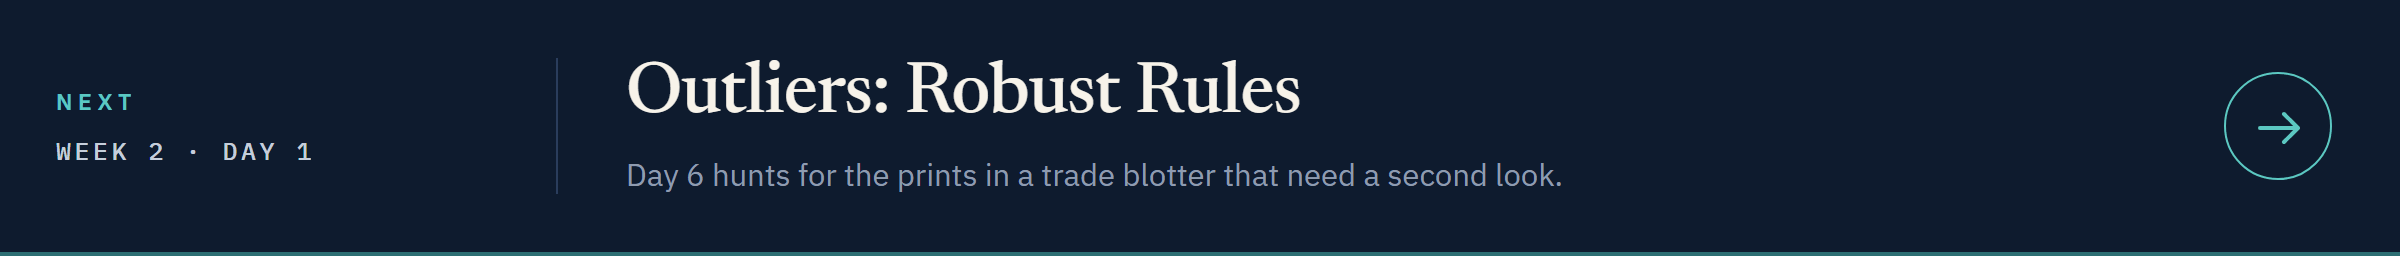](../../week2/day1/06_outliers_robust_rules.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05c_risk_models/week2/day1/06_outliers_robust_rules.ipynb)